# Concept regions against the linear CAV (Work 4)

Question: on the same rule target, examples, class weights and patient roles, does one CAR-style RBF region probe recognise concept membership differently from the Work 3 linear classifier, at the reference year and after frozen transfer?

Steps follow the approved plan §5 (steps 0 to 7). Each step is one question with a markdown line, its computation and a plot. Reusable functions are in `concept_regions.py` (`cr`) and `concept_candidates.py` (`cc`), with tests in `tests/test_concept_regions.py`.

Settings: `CONCEPT_REGIONS_BUILDS=pilot` runs only the pilot build (last_3 2011). The default runs all 11 builds. Nothing else changes between the two.


In [1]:
import hashlib
import json
import os
import pickle
import resource
import shutil
import subprocess
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
import torch
from IPython.display import display
from joblib import Parallel, delayed
from sklearn.metrics import roc_auc_score

import concept_candidates as cc
import concept_regions as cr
from concept_study import alternative_bases as ab, loading, paths
from semantic_rules import RuleSet

ALL_BUILDS = [("all_history", 2008), ("all_history", 2009), ("all_history", 2010), ("all_history", 2011),
              ("all_history", 2012), ("all_history", 2013), ("last_3", 2010), ("last_3", 2011),
              ("last_3", 2012), ("last_3", 2013), ("r1", 2007)]
BUILD_SETS = {"all": ALL_BUILDS, "pilot": [("last_3", 2011)]}
BUILD_SET = os.environ.get("CONCEPT_REGIONS_BUILDS", "all")
BUILDS = BUILD_SETS[BUILD_SET]
TRANSFER_YEARS = (2012, 2013, 2014)
REPRESENTATION_ONLY_YEAR = 2015
POOLS = ("literal", "eligible")
PRIMARY_POOL = "literal"
PROBES = ("linear", "tuned", "region")
PROBE_PAIRS = (("region", "linear"), ("tuned", "linear"), ("region", "tuned"))
WORKERS = 24
GPU_SMOKE_ATOL = 1e-12
OUTPUT = Path(os.environ["RPI_OUT_DIR"]).resolve()
OUTPUT.mkdir(parents=True, exist_ok=True)
STARTED = time.time()
ERRORS, TIMINGS, GPU_LOG, STATE = [], {}, {}, {}
print("build set:", BUILD_SET, "| builds:", len(BUILDS), "| output:", OUTPUT)
print("grid from concept_regions:", cr.PREPROCESSING, cr.C_GRID, cr.WIDTH_MULTIPLIERS)


build set: all | builds: 11 | output: /home/rafaelgomes/SAE-TCAV/stats/concept_agreement_study/extensions/concept_regions/full
grid from concept_regions: ('raw', 'standardised') (0.01, 0.1, 1, 10, 100) (0.25, 0.5, 1, 2, 4)


In [2]:
def save(fig, name):
    fig.tight_layout()
    fig.savefig(OUTPUT / f"{name}.png", dpi=120)
    plt.show()


def table(frame, name, show=True):
    frame.to_csv(OUTPUT / f"{name}.csv", index=False)
    if show:
        display(frame)


def usable():
    return [key for key, state in STATE.items() if state["ok"]]


def fail(key, step, error):
    ERRORS.append({"build": key[0], "reference": key[1], "step": step, "error": f"{type(error).__name__}: {error}"[:400]})
    if key in STATE:
        STATE[key]["ok"] = False
    print("ERROR", key, step, ERRORS[-1]["error"])


def tag(*parts):
    """Key of the Work 3 archives: parts joined by |, with / replaced by ~."""
    return "|".join(str(p).replace("/", "~") for p in parts)


## Step 0. Hash gate and provenance

Question: are the frozen Work 3 inputs the ones the approved plan names? A mismatch on a gated input stops the run before anything is loaded. Other hashes are recorded only.


In [3]:
ROOT = paths.CODE_ROOT
RUN_FILES = paths.OUTPUT / "extensions/concept_candidates/full"
GATE = {
    "rules.json": (RUN_FILES / "rules.json", "5617d2c1e86d589686fa421cb077817cc4c3a33e2bffc24ac9b6a961b1d8ac87"),
    "cav_classifiers.npz": (RUN_FILES / "cav_classifiers.npz", "894387f5d529a1d074871f8f3a70046226b6cc73dcbf6dd4e6bcebbcc85f6362"),
    "private/fit_rows.npz": (RUN_FILES / "private/fit_rows.npz", "4ddc601e160b065ec51eeb39758297b40799ec0ecbdbbd37e901ea8ba34867cd"),
    "concept_candidates.py": (ROOT / "concept_candidates.py", "2ecc6a9df44fe191c9af21ac105ad38b38ec9b699969e821ac9586d711cbef36"),
    "patient_table/index.json": (paths.PATIENT_TABLE / "index.json", "46a5434c39671ef452307bf72b99711cd54bd22d2dcc58a2af3815820aaecbe1"),
    "temporal robustness population": (paths.POPULATION, "c8804591c93087241b9533dce77dd54b2f1e77b23a36400527459cfa8f99add7"),
}
gate_rows = [{"input": name, "sha256": cr.sha256(path), "matches_plan": cr.sha256(path) == expected}
             for name, (path, expected) in GATE.items()]
display(pd.DataFrame(gate_rows))
if not all(row["matches_plan"] for row in gate_rows):
    raise RuntimeError("a gated input differs from the approved plan: run stopped before loading")


,input,sha256,matches_plan
0,rules.json,5617d2c1e86d589686fa421cb077817cc4c3a33e2bffc2...,True
1,cav_classifiers.npz,894387f5d529a1d074871f8f3a70046226b6cc73dcbf6d...,True
2,private/fit_rows.npz,4ddc601e160b065ec51eeb39758297b40799ec0ecbdbbd...,True
3,concept_candidates.py,2ecc6a9df44fe191c9af21ac105ad38b38ec9b699969e8...,True
4,patient_table/index.json,46a5434c39671ef452307bf72b99711cd54bd22d2dcc58...,True
5,temporal robustness population,c8804591c93087241b9533dce77dd54b2f1e77b23a3640...,True


In [4]:
concept_files = sorted((paths.PATIENT_TABLE / "concepts").glob("*.npz"))
RECORDED = {
    "candidates.csv": cr.sha256(RUN_FILES / "candidates.csv"),
    "Work 3 run.json": cr.sha256(RUN_FILES / "run.json"),
    "Work 3 descriptions.csv (rule against A, joined to recognition)": cr.sha256(RUN_FILES / "descriptions.csv"),
    "patient_table/concepts/*.npz (one combined hash)": hashlib.sha256(
        "".join(cr.sha256(p) for p in concept_files).encode()).hexdigest(),
    "alternative_bases/concepts.csv": cr.sha256(paths.OUTPUT / "extensions/alternative_bases/concepts.csv"),
    "repo modules imported": {str(m.__file__): cr.sha256(m.__file__) for m in list(sys.modules.values())
                              if str(getattr(m, "__file__", None) or "").startswith(str(ROOT))
                              and "site-packages" not in str(m.__file__)
                              and not str(m.__file__).startswith(str(ROOT / ".venv"))},
}
print("recorded (no gate):", len(RECORDED["repo modules imported"]), "repo modules hashed;", len(concept_files), "concept files")


recorded (no gate): 13 repo modules hashed; 95 concept files


Question: is a CUDA GPU free for the batched AUROC readouts? The run stops if CUDA is missing, so no step falls back to CPU without a record.


In [5]:
if not torch.cuda.is_available():
    raise RuntimeError("CUDA unavailable: stop and report (no silent CPU fallback)")
free_gpu, total_gpu = torch.cuda.mem_get_info()
free_disk = shutil.disk_usage(ROOT).free
ENVIRONMENT = {"gpu": torch.cuda.get_device_name(0), "gpu_free_mib_start": int(free_gpu // 2**20),
               "gpu_total_mib": int(total_gpu // 2**20), "free_disk_gib_start": round(free_disk / 2**30, 1),
               "sklearn": sklearn.__version__, "torch": torch.__version__}
print(ENVIRONMENT)


{'gpu': 'NVIDIA GeForce RTX 2080', 'gpu_free_mib_start': 7845, 'gpu_total_mib': 7972, 'free_disk_gib_start': 97.5, 'sklearn': '1.5.2', 'torch': '2.1.2+cu121'}


## Step 0b. Inputs and the single draw set

Question: which patients does each bootstrap draw resample? One draw set serves the whole study (plan decision 10): a patient has the same count in every build, year and probe, and the intervals are patient-cluster intervals over the population.


In [6]:
inputs = loading.open_inputs()
population = inputs["population"]
POPULATION_IDS = np.asarray(population["patient_id"]).astype(str)
UNIQUE_IDS = np.unique(POPULATION_IDS)
DRAW_COUNTS = cc.patient_weights(UNIQUE_IDS, cc.BOOTSTRAP_SEEDS).astype(np.int32)
index = json.load(open(paths.PATIENT_TABLE / "index.json"))
print("population patients:", len(UNIQUE_IDS), "| draw counts:", DRAW_COUNTS.shape,
      "| seeds", cc.BOOTSTRAP_SEEDS[0], "to", cc.BOOTSTRAP_SEEDS[-1])


population patients: 5636 | draw counts: (500, 5636) | seeds 3001 to 3500


## Step 1. Load each build and check the exact anchors

Question: do the rebuilt objects equal the frozen Work 3 objects? Exact anchors (a mismatch stops that build only): fitting, selection and evaluation positions; patient and year alignment with the patient table; the frozen rule equals `in_R`; and the declared replay of every SAE concept (literal and eligible pools) and of every random candidate with a measured literal declared classifier.


In [7]:
CONCEPT_FILE = {c["concept"]: c["file"] for c in index["concepts"]}
PANEL = {(r["build"], r["reference"]): ("primary" if "last_3" in r["variants"] else "auxiliary") for r in index["builds"]}
RULES = json.load(open(RUN_FILES / "rules.json"))
CLASSIFIERS = np.load(RUN_FILES / "cav_classifiers.npz")
FIT_ROWS = np.load(RUN_FILES / "private/fit_rows.npz")
EXACT = ("fit_positions", "selection_positions", "evaluation_positions", "patient_alignment", "year_alignment",
         "random_count_matches")


def saved_declared(name, pool):
    """The declared classifier saved by Work 3: status, support, and coef and intercept when measured."""
    status = str(CLASSIFIERS[tag(name, pool, "declared_status")])
    saved = {"status": status, "support": [int(v) for v in CLASSIFIERS[tag(name, pool, "declared_support")]]}
    if status == "measured":
        saved["coef"] = CLASSIFIERS[tag(name, pool, "declared_coef")]
        saved["intercept"] = float(CLASSIFIERS[tag(name, pool, "declared_intercept")])
    return saved


ANCHORS = []
for build, reference in BUILDS:
    key, started = (build, reference), time.time()
    anchor = {"build": build, "reference": reference, "panel": PANEL[key]}
    try:
        record = next(r for r in index["builds"] if (r["build"], r["reference"]) == key)
        items = [i for i in inputs["inventory"] if (i["build"], i["reference"]) == key]
        frozen_roles, cache = items[0]["roles"], inputs["caches"][build]
        cc.reference_roles(population, cache, reference, frozen_roles)
        bases = cc.load_build_two_modes(inputs, build, reference, frozen_roles)
        dev, ev = bases["develop"], bases["evaluate"]
        data = ab.reference_data(inputs, record)
        E = np.flatnonzero(ev["roles"] == "evaluation")
        cav = np.flatnonzero((dev["years"] == reference) & (dev["roles"] == "cav_fit"))
        sel = np.flatnonzero((dev["years"] == reference) & (dev["roles"] == "concept_selection"))
        ref_ev = E[ev["years"][E] == reference]
        anchor["fit_positions"] = bool(np.array_equal(dev["row_index"][cav], FIT_ROWS[tag(build, reference, "cav_fit")]))
        anchor["selection_positions"] = bool(np.array_equal(dev["row_index"][sel], FIT_ROWS[tag(build, reference, "selection")]))
        anchor["evaluation_positions"] = bool(np.array_equal(ev["row_index"][ref_ev], FIT_ROWS[tag(build, reference, "evaluation")]))
        anchor["patient_alignment"] = bool(np.array_equal(ev["patients"][E].astype(str), data["table"]["patient_id"].astype(str)))
        anchor["year_alignment"] = bool(np.array_equal(ev["years"][E], data["table"]["year"]))

        concepts = []
        for item in items:
            name = loading.concept_key(build, reference, item["family"])
            unit_dev = loading.concept_unit(bases["develop_inputs"], dev, item)
            unit_ev = loading.concept_unit(inputs, ev, item)
            frame = np.load(paths.PATIENT_TABLE / "concepts" / CONCEPT_FILE[name])
            fit = {"X": dev["embeddings"][cav], "rule": unit_dev["rule_mask"][cav],
                   "activation": unit_dev["activation"][cav], "patients": dev["patients"][cav]}
            concept = {"concept": name, "source": "sae", "fit": fit, "pools": POOLS,
                       "selection": {"X": dev["embeddings"][sel], "rule": unit_dev["rule_mask"][sel],
                                     "patients": dev["patients"][sel]},
                       "evaluation": {"X": ev["embeddings"][E], "rule": frame["in_R"], "in_A": frame["in_A"],
                                      "activation": unit_ev["activation"][E], "patients": ev["patients"][E],
                                      "years": ev["years"][E]},
                       "saved": {pool: saved_declared(name, pool) for pool in POOLS}}
            concept["in_R_equal"] = bool(np.array_equal(frame["in_R"], unit_ev["rule_mask"][E]))
            concept["replay"] = {pool: cr.declared_matches(
                cc.declared_fit(fit["X"], fit["rule"], fit["activation"], fit["patients"], pool), saved)
                for pool, saved in concept["saved"].items()}
            concept["activation_gap"] = float(np.max(np.abs(frame["activation"] - unit_ev["activation"][E])))
            concepts.append(concept)

        for name, entry in RULES.items():
            if entry["build"] != build or entry["reference"] != reference or not entry["source"].startswith("random"):
                continue
            saved = {"literal": saved_declared(name, "literal")}
            if saved["literal"]["status"] != "measured":
                anchor["random_without_measured_literal"] = anchor.get("random_without_measured_literal", 0) + 1
                continue
            rule = RuleSet.from_dict(entry["rule"])
            fit = {"X": dev["embeddings"][cav], "rule": rule.mask(dev["X"][cav]),
                   "activation": np.full(len(cav), np.nan), "patients": dev["patients"][cav]}
            concept = {"concept": name, "source": entry["source"], "fit": fit, "pools": ("literal",),
                       "selection": {"X": dev["embeddings"][sel], "rule": rule.mask(dev["X"][sel]),
                                     "patients": dev["patients"][sel]},
                       "evaluation": {"X": ev["embeddings"][E], "rule": rule.mask(ev["X"][E]), "in_A": None,
                                      "activation": np.full(len(E), np.nan), "patients": ev["patients"][E],
                                      "years": ev["years"][E]},
                       "saved": saved, "in_R_equal": None, "activation_gap": None}
            concept["replay"] = {"literal": cr.declared_matches(
                cc.declared_fit(fit["X"], fit["rule"], fit["activation"], fit["patients"], "literal"), saved["literal"])}
            concepts.append(concept)

        anchor["sae_concepts"] = sum(c["source"] == "sae" for c in concepts)
        anchor["random_candidates"] = sum(c["source"] != "sae" for c in concepts)
        anchor["random_measured_literal"] = sum(
            saved_declared(name, "literal")["status"] == "measured" for name, entry in RULES.items()
            if entry["build"] == build and entry["reference"] == reference and entry["source"].startswith("random"))
        anchor["random_count_matches"] = anchor["random_candidates"] == anchor["random_measured_literal"]
        anchor["in_R_mismatches"] = sum(c["in_R_equal"] is False for c in concepts)
        anchor["replay_failures"] = sum(not ok for c in concepts for ok in c["replay"].values())
        anchor["exact_anchors_hold"] = bool(all(anchor[k] for k in EXACT) and anchor["in_R_mismatches"] == 0
                                            and anchor["replay_failures"] == 0)
        anchor["activation_max_gap_descriptive"] = max([c["activation_gap"] for c in concepts if c["activation_gap"] is not None] or [np.nan])
        STATE[key] = {"ok": anchor["exact_anchors_hold"], "panel": PANEL[key], "concepts": concepts, "ev": ev,
                      "E": E, "cav": cav, "sel": sel, "reference": reference, "build": build,
                      "split_seed": cache.config["split_seed"]}
        if not anchor["exact_anchors_hold"]:
            fail(key, "1 exact anchors", ValueError(f"exact anchor mismatch: {anchor}"))
        print(key, "SAE concepts", anchor["sae_concepts"], "random", anchor["random_candidates"],
              "exact anchors hold:", anchor["exact_anchors_hold"], f"{time.time() - started:.0f}s")
    except Exception as error:
        anchor["exact_anchors_hold"] = False
        fail(key, "1 load and anchors", error)
    ANCHORS.append(anchor)
    TIMINGS[f"1 {build} {reference}"] = time.time() - started


/home/rafaelgomes/SAE-TCAV/.venv/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


('all_history', 2008) SAE concepts 6 random 25 exact anchors hold: True 2s


('all_history', 2009) SAE concepts 10 random 41 exact anchors hold: True 1s


('all_history', 2010) SAE concepts 8 random 43 exact anchors hold: True 1s


('all_history', 2011) SAE concepts 7 random 31 exact anchors hold: True 0s


('all_history', 2012) SAE concepts 11 random 33 exact anchors hold: True 1s


... (2 outputs left out)

('last_3', 2011) SAE concepts 14 random 31 exact anchors hold: True 1s


('last_3', 2012) SAE concepts 7 random 35 exact anchors hold: True 1s


('last_3', 2013) SAE concepts 14 random 25 exact anchors hold: True 1s


('r1', 2007) SAE concepts 4 random 24 exact anchors hold: True 0s


,build,reference,panel,fit_positions,selection_positions,evaluation_positions,patient_alignment,year_alignment,random_without_measured_literal,sae_concepts,random_candidates,random_measured_literal,random_count_matches,in_R_mismatches,replay_failures,exact_anchors_hold,activation_max_gap_descriptive
0,all_history,2008,primary,True,True,True,True,True,3.0,6,25,25,True,0,0,True,0.0
1,all_history,2009,primary,True,True,True,True,True,1.0,10,41,41,True,0,0,True,0.0
2,all_history,2010,auxiliary,True,True,True,True,True,1.0,8,43,43,True,0,0,True,0.0
3,all_history,2011,auxiliary,True,True,True,True,True,2.0,7,31,31,True,0,0,True,0.0
4,all_history,2012,auxiliary,True,True,True,True,True,2.0,11,33,33,True,0,0,True,0.0
5,all_history,2013,auxiliary,True,True,True,True,True,1.0,7,38,38,True,0,0,True,0.0
6,last_3,2010,primary,True,True,True,True,True,2.0,7,31,31,True,0,0,True,0.0
7,last_3,2011,primary,True,True,True,True,True,2.0,14,31,31,True,0,0,True,0.0
8,last_3,2012,primary,True,True,True,True,True,3.0,7,35,35,True,0,0,True,0.0
9,last_3,2013,primary,True,True,True,True,True,1.0,14,25,25,True,0,0,True,0.0


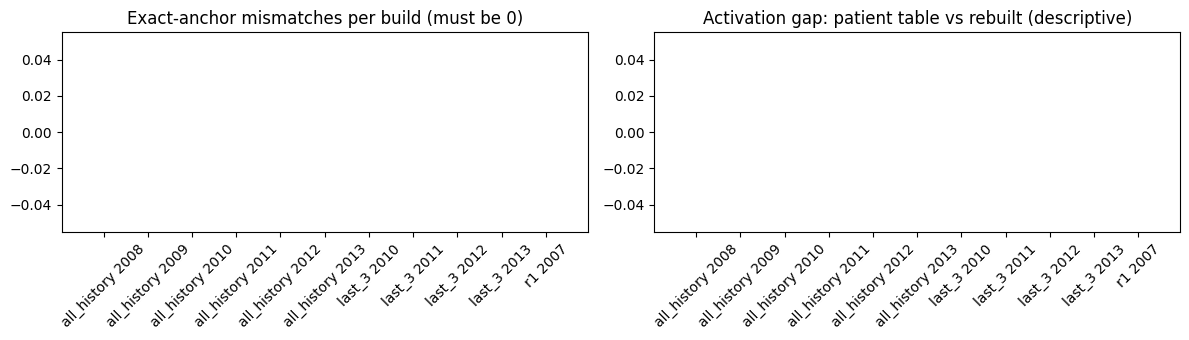

In [8]:
anchors_df = pd.DataFrame(ANCHORS)
table(anchors_df, "anchors")
mismatches = [sum(not a.get(k, False) for k in EXACT) + a.get("in_R_mismatches", 0) + a.get("replay_failures", 0)
              for a in ANCHORS]
fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
labels = [f"{a['build']} {a['reference']}" for a in ANCHORS]
axes[0].bar(labels, mismatches, color="C3")
axes[0].set_title("Exact-anchor mismatches per build (must be 0)")
axes[1].bar(labels, anchors_df.activation_max_gap_descriptive.astype(float), color="C1")
axes[1].set_title("Activation gap: patient table vs rebuilt (descriptive)")
for ax in axes:
    ax.tick_params(axis="x", rotation=45)
save(fig, "step1_anchors")


## Step 1b. Descriptive anchors

Question: how close are the recomputed agreement P(A | R) per year and the median fit AUROC to Work 3's saved tables? Gaps are reported and do not stop the run (plan §5 step 1).


max agreement gap: 5.217391307876795e-08 | max median-AUROC gap: 2.220446049250313e-16 | rows: 190


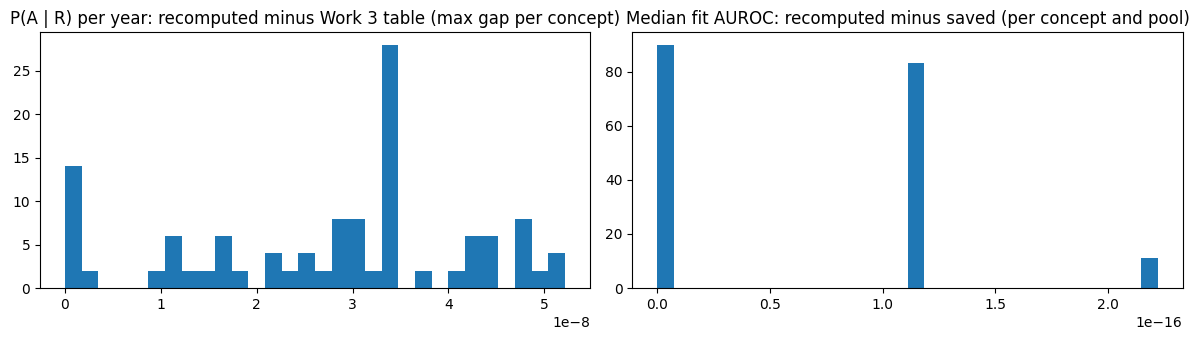

In [9]:
EVAL_BY_CONCEPT = pd.read_csv(RUN_FILES / "evaluation_by_concept.csv")
ALT_SAE = pd.read_csv(paths.OUTPUT / "extensions/alternative_bases/concepts.csv")
ALT_SAE = ALT_SAE[(ALT_SAE.basis == "sae") & (ALT_SAE["draw"] == 0)]
DESCRIPTIVE = []
for key in usable():
    state = STATE[key]
    build, reference = key
    ev, E = state["ev"], state["E"]
    years_E = ev["years"][E]
    ref_pos = np.flatnonzero(years_E == reference)
    for c in [c for c in state["concepts"] if c["source"] == "sae"]:
        in_R = np.asarray(c["evaluation"]["rule"], bool)
        in_A = np.asarray(c["evaluation"]["in_A"], bool)
        alt = ALT_SAE[(ALT_SAE.build == build) & (ALT_SAE.reference == reference) & (ALT_SAE.concept == c["concept"])]
        agreement_gaps = []
        for year in np.unique(years_E):
            at = years_E == year
            if in_R[at].sum() and len(alt) == 1 and np.isfinite(alt[f"agreement_{int(year)}"].iloc[0]):
                recomputed = (in_A & in_R)[at].sum() / in_R[at].sum()
                agreement_gaps.append(abs(recomputed - float(alt[f"agreement_{int(year)}"].iloc[0])))
        X_ref, rule_ref = c["evaluation"]["X"][ref_pos], in_R[ref_pos]
        for pool in POOLS:
            coef, intercept = CLASSIFIERS[tag(c["concept"], pool, "coef")], CLASSIFIERS[tag(c["concept"], pool, "intercept")]
            aucs = [cc.auroc(rule_ref, X_ref @ coef[f].astype(float) + intercept[f])
                    for f in range(coef.shape[0]) if np.isfinite(coef[f]).all()]
            aucs = [a for a in aucs if a is not None]
            saved_row = EVAL_BY_CONCEPT[(EVAL_BY_CONCEPT.build == build) & (EVAL_BY_CONCEPT.reference == reference)
                                        & (EVAL_BY_CONCEPT.source == "sae") & (EVAL_BY_CONCEPT.concept == c["concept"])
                                        & (EVAL_BY_CONCEPT.pool == pool)]
            recomputed_median = float(np.median(aucs)) if aucs else np.nan
            saved_median = float(saved_row.auroc_all.iloc[0]) if len(saved_row) == 1 else np.nan
            DESCRIPTIVE.append({"build": build, "reference": reference, "concept": c["concept"], "pool": pool,
                                "agreement_max_gap": max(agreement_gaps) if agreement_gaps else np.nan,
                                "median_auroc_recomputed": recomputed_median, "median_auroc_saved": saved_median,
                                "median_auroc_gap": abs(recomputed_median - saved_median)})
descriptive_df = pd.DataFrame(DESCRIPTIVE)
table(descriptive_df, "anchors_descriptive", show=False)
print("max agreement gap:", descriptive_df.agreement_max_gap.max(), "| max median-AUROC gap:",
      descriptive_df.median_auroc_gap.max(), "| rows:", len(descriptive_df))
fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
axes[0].hist(descriptive_df.agreement_max_gap.dropna(), bins=30)
axes[0].set_title("P(A | R) per year: recomputed minus Work 3 table (max gap per concept)")
axes[1].hist(descriptive_df.median_auroc_gap.dropna(), bins=30)
axes[1].set_title("Median fit AUROC: recomputed minus saved (per concept and pool)")
save(fig, "step1b_descriptive_anchors")


## Step 2. Fits: 50 region and 10 linear settings per concept and pool

Question: how does each of the 60 settings fit on the `cav_fit` rows and score on the `concept_selection` rows? CPU only: the SVC and liblinear fits are scikit-learn (plan §7a). One joblib task per concept and pool, 24 workers, one BLAS thread each. The fixed linear probe is the saved declared classifier; its raw C = 0.1 refit must reproduce it exactly.


In [10]:
JOBS = [(key, c, pool) for key in usable() for c in STATE[key]["concepts"] for pool in c["pools"]]
started = time.time()
FITTED = Parallel(n_jobs=WORKERS)(
    delayed(cr.fit_concept_task)(c["fit"]["X"], c["fit"]["rule"], c["fit"]["activation"], c["fit"]["patients"],
                                 c["selection"]["X"], c["selection"]["rule"], pool)
    for key, c, pool in JOBS)
for (key, c, pool), result in zip(JOBS, FITTED):
    c.setdefault("fits", {})[pool] = result
TIMINGS["2 fits"] = time.time() - started
fixed_checks = []
for key, c, pool in JOBS:
    if pool == "literal" and c["saved"]["literal"]["status"] == "measured":
        fixed = c["fits"]["literal"]["fixed_linear"]
        fixed_checks.append(fixed is not None and bool(np.array_equal(
            fixed.named_steps["classifier"].coef_[0], c["saved"]["literal"]["coef"])))
print("fit tasks:", len(JOBS), "| seconds:", round(TIMINGS["2 fits"], 1),
      "| raw C=0.1 refit equals saved literal coef:", sum(fixed_checks), "of", len(fixed_checks))


fit tasks: 547 | seconds: 16.7 | raw C=0.1 refit equals saved literal coef: 449 of 449


## Step 3. Choice on selection rows and the tuning surface

Question: which setting does each probe choose, and how does selection AUROC move across the surface? Only `concept_selection` rows are scored here. The full surface, the chosen flag, the rule that chose it and the selection-row patient counts go to `tuning.csv`.


In [11]:
TUNING = []
# The module names the tuned linear probe "linear". Outputs use "tuned_linear", so "linear" always means the fixed declared probe.
TUNED_LABEL = {"region": "region", "linear": "tuned_linear"}
for key, c, pool in JOBS:
    build, reference = key
    result = c["fits"][pool]
    sel_rule = np.asarray(c["selection"]["rule"], bool)
    sel_patients = c["selection"]["patients"]
    choice = {probe: result[probe] for probe in ("region", "linear")}
    ident = {"build": build, "reference": reference, "panel": STATE[key]["panel"], "source": c["source"],
             "concept": c["concept"], "pool": pool,
             "selection_positive_patients": len(np.unique(sel_patients[sel_rule])),
             "selection_negative_patients": len(np.unique(sel_patients[~sel_rule]))}
    for row in result["tuning"]:
        probe = row["probe"]
        TUNING.append({**ident, **{k: str(v) if k == "position" else v for k, v in row.items()}, "probe": TUNED_LABEL[probe],
                       "choice_rule": choice[probe]["rule"], "choice_tied": choice[probe]["tied"],
                       "choice_excluded": choice[probe]["excluded"]})
tuning_df = pd.DataFrame(TUNING)
table(tuning_df, "tuning", show=False)
print(tuning_df.groupby(["probe", "status"]).size().rename("settings").to_string())
chosen = tuning_df[tuning_df.chosen]
print("chosen settings:", len(chosen), "| rules:", chosen.choice_rule.value_counts().to_dict())


probe         status     
region        measured       27050
              unsupported      300
tuned_linear  measured        5410
              unsupported       60
chosen settings: 1082 | rules: {'max': 598, 'tie: nearest grid setting': 386, 'tie: anchor': 88, 'default: selection undefined': 10}


,source,panel,pool,region,tuned_linear,concepts
0,random1,auxiliary,literal,raw,raw,7
1,random1,auxiliary,literal,raw,standardised,4
2,random1,auxiliary,literal,standardised,raw,6
3,random1,auxiliary,literal,standardised,standardised,18
4,random1,primary,literal,raw,raw,5
5,random1,primary,literal,raw,standardised,7
6,random1,primary,literal,standardised,raw,10
7,random1,primary,literal,standardised,standardised,25
8,random2,auxiliary,literal,raw,raw,4
9,random2,auxiliary,literal,raw,standardised,4


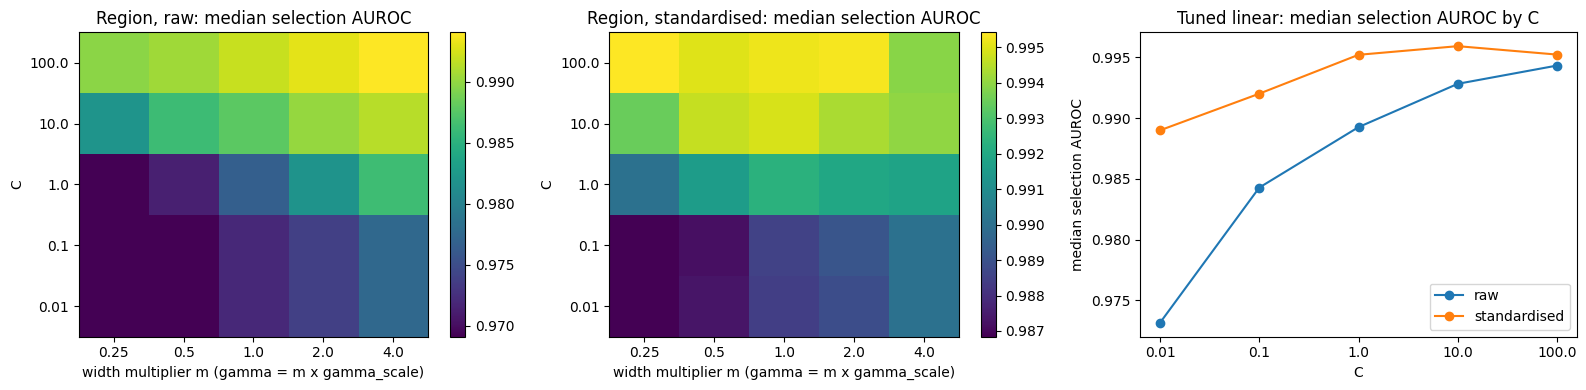

In [12]:
chosen_wide = chosen.pivot_table(index=["build", "reference", "panel", "source", "concept", "pool"], columns="probe",
                                 values="preprocessing", aggfunc="first").reset_index()
PREPROCESSING_CHOICES = (chosen_wide.groupby(["source", "panel", "pool", "region", "tuned_linear"], dropna=False).size()
                         .rename("concepts").reset_index())
table(PREPROCESSING_CHOICES, "preprocessing_choices")
measured = tuning_df[(tuning_df.status == "measured") & tuning_df.selection_auroc.notna() & (tuning_df.pool == PRIMARY_POOL)]
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, preprocessing in zip(axes[:2], cr.PREPROCESSING):
    surface = measured[(measured.probe == "region") & (measured.preprocessing == preprocessing)]
    grid = surface.pivot_table(index="C", columns="width_multiplier", values="selection_auroc", aggfunc="median")
    image = ax.imshow(grid.values, origin="lower", aspect="auto", cmap="viridis")
    ax.set_xticks(range(grid.shape[1]), [str(v) for v in grid.columns]); ax.set_yticks(range(grid.shape[0]), [str(v) for v in grid.index])
    ax.set_xlabel("width multiplier m (gamma = m x gamma_scale)"); ax.set_ylabel("C")
    ax.set_title(f"Region, {preprocessing}: median selection AUROC")
    plt.colorbar(image, ax=ax)
linear = measured[measured.probe == "tuned_linear"]
for preprocessing, frame in linear.groupby("preprocessing"):
    medians = frame.groupby("C").selection_auroc.median()
    axes[2].plot(range(len(medians)), medians.values, marker="o", label=preprocessing)
axes[2].set_xticks(range(len(medians)), [str(v) for v in medians.index])
axes[2].set_xlabel("C"); axes[2].set_ylabel("median selection AUROC"); axes[2].legend()
axes[2].set_title("Tuned linear: median selection AUROC by C")
save(fig, "step3_tuning_surface")


## Step 4. Reference recognition on the GPU: a check first

Question: do the batched GPU AUROCs equal sklearn on real pilot scores? The first usable concept's region, tuned and linear scores on reference-year rows are checked, with the same draw weights, to 1e-12 (plan §11). A mismatch or NaN pattern difference stops the run.


In [13]:
def probe_scores(concept, pool, X):
    """Decision scores of the probes on rows X: the saved declared classifier (replayed exactly), the tuned linear and the region probe. Absent where a probe is not measured."""
    fits, saved = concept["fits"][pool], concept["saved"][pool]
    scores = {}
    if saved["status"] == "measured":
        scores["linear"] = cr.decision_scores((saved["coef"], saved["intercept"]), X)
    for name, choice in (("tuned", fits["linear"]), ("region", fits["region"])):
        setting = choice["setting"]
        if setting is not None and setting["status"] == "measured":
            scores[name] = cr.decision_scores(setting["pipeline"], X)
    return scores


def sklearn_weighted_auroc(labels, scores, weights):
    try:
        return roc_auc_score(labels, scores, sample_weight=weights)
    except ValueError:
        return np.nan


first = usable()[0]
c0 = next(c for c in STATE[first]["concepts"] if c["source"] == "sae")
rows_ref = np.flatnonzero(cr.scoring_rows(STATE[first]["ev"]["roles"], STATE[first]["ev"]["years"], (first[1],)))
pos_ref = np.searchsorted(STATE[first]["E"], rows_ref)
labels_ref = np.asarray(c0["evaluation"]["rule"], bool)[pos_ref].astype(int)
scores_ref = probe_scores(c0, PRIMARY_POOL, c0["evaluation"]["X"][pos_ref])
names_ref = list(scores_ref)
S = np.stack([scores_ref[n] for n in names_ref])
W = np.vstack([np.ones((1, len(rows_ref))), cr.draw_counts_for_rows(DRAW_COUNTS, POPULATION_IDS,
                                                                    STATE[first]["ev"]["patients"][rows_ref])])
torch.cuda.reset_peak_memory_stats()
gpu_values = cc.weighted_auroc(labels_ref, S, W)
sklearn_values = np.array([[sklearn_weighted_auroc(labels_ref, S[i], w) for w in W] for i in range(len(names_ref))])
nan_pattern_equal = bool(np.array_equal(np.isnan(gpu_values), np.isnan(sklearn_values)))
gpu_gap = float(np.nanmax(np.abs(gpu_values - sklearn_values)))
GPU_SMOKE = {"build": first[0], "reference": first[1], "concept": c0["concept"], "probes": names_ref,
             "rows": int(len(rows_ref)), "draws": int(W.shape[0] - 1), "max_gap": gpu_gap,
             "nan_pattern_equal": nan_pattern_equal, "atol": GPU_SMOKE_ATOL,
             "peak_allocated_mib": int(torch.cuda.max_memory_allocated() // 2**20)}
print(GPU_SMOKE)
if not (gpu_gap <= GPU_SMOKE_ATOL and nan_pattern_equal):
    raise RuntimeError("GPU AUROC differs from sklearn: stop and report")


{'build': 'all_history', 'reference': 2008, 'concept': 'all_history/2008/2008/42/42:0,135:24,215:233', 'probes': ['linear', 'tuned', 'region'], 'rows': 298, 'draws': 500, 'max_gap': 2.220446049250313e-16, 'nan_pattern_equal': True, 'atol': 1e-12, 'peak_allocated_mib': 35}


## Step 4 (cont.). Reference-year recognition, recall and membership

Question: at the reference year, how well does each probe recognise R on all rule-labelled evaluation rows, and on the restricted stratum, with paired patient-cluster intervals? The same loop runs for the later years (step 5). Each concept and pool is one batched GPU call per population; batch sizes come from `cc.batch_size` (at most half the free memory).


In [14]:
VALUES = {}
COVERAGE, SCORE_QUANTILES = [], []


def years_for(reference):
    """Reference year, then the transfer years after it, and the representation-only year."""
    return [reference] + [y for y in (*TRANSFER_YEARS, REPRESENTATION_ONLY_YEAR) if y > reference]


def stage_of(year, reference):
    if year == reference:
        return "reference"
    return "representation only" if year == REPRESENTATION_ONLY_YEAR else "transfer"


def probe_status(concept, pool):
    fits, saved = concept["fits"][pool], concept["saved"][pool]
    status = {"linear": saved["status"]}
    for name, choice in (("tuned", fits["linear"]), ("region", fits["region"])):
        status[name] = "none" if choice["setting"] is None else choice["setting"]["status"]
    return status


for key in usable():
    build, reference = key
    state, started = STATE[key], time.time()
    cc.BATCH_LOG.clear()
    torch.cuda.reset_peak_memory_stats()
    free_before = int(torch.cuda.mem_get_info()[0] // 2**20)
    try:
        ev, E = state["ev"], state["E"]
        for year in years_for(reference):
            rows_ev = np.flatnonzero(cr.scoring_rows(ev["roles"], ev["years"], (year,)))
            pos = np.searchsorted(E, rows_ev)
            patients_y = ev["patients"][rows_ev]
            weights_y = cr.draw_counts_for_rows(DRAW_COUNTS, POPULATION_IDS, patients_y).astype(float)
            for c in state["concepts"]:
                evaluation = c["evaluation"]
                X = evaluation["X"][pos]
                rule = np.asarray(evaluation["rule"], bool)[pos]
                in_A = None if evaluation["in_A"] is None else np.asarray(evaluation["in_A"], bool)[pos]
                populations = cc.scoring_populations(rule, evaluation["activation"][pos], patients_y,
                                                     cr.restricted_cutoff(c["fit"]["activation"]))
                names = ("all", "restricted") if c["source"] == "sae" else ("all",)
                for pool in c["pools"]:
                    scores = probe_scores(c, pool, X)
                    status = probe_status(c, pool)
                    measured_probes = [p for p in PROBES if p in scores]
                    for population in names:
                        rows = populations[population]["rows"]
                        labels, W = rule[rows], weights_y[:, rows]
                        Wp = np.vstack([np.ones((1, len(rows))), W])
                        base = (build, reference, c["source"], c["concept"], pool, year, population)
                        nan_draws = np.full(Wp.shape[0], np.nan)
                        for p in PROBES:
                            VALUES[base + (f"auroc:{p}",)] = nan_draws.copy()
                        if measured_probes:
                            boot = cc.bootstrap_auroc(labels, {p: scores[p][rows] for p in measured_probes}, W)
                            for p in measured_probes:
                                point = boot["point"][p]
                                VALUES[base + (f"auroc:{p}",)] = np.r_[np.nan if point is None else point, boot["draws"][p]]
                        if population == "all":
                            in_A_rows = in_A[rows] if in_A is not None else np.zeros(len(rows), bool)
                            for p in PROBES:
                                for quantity in ("recall", "members", "precision", "p_a_member"):
                                    VALUES[base + (f"{quantity}:{p}",)] = nan_draws.copy()
                            for p in measured_probes:
                                member = cr.membership(labels, scores[p][rows], Wp, in_A_rows)
                                VALUES[base + (f"recall:{p}",)] = member["recall"]
                                VALUES[base + (f"members:{p}",)] = member["members"]
                                VALUES[base + (f"precision:{p}",)] = member["precision"]
                                if in_A is not None:
                                    VALUES[base + (f"p_a_member:{p}",)] = member["p_a_given_member"]
                            for a, b in PROBE_PAIRS:
                                both = a in measured_probes and b in measured_probes
                                VALUES[base + (f"jaccard:{a}-{b}",)] = (cr.members_jaccard(scores[a][rows], scores[b][rows], Wp)
                                                                       if both else nan_draws.copy())
                            if in_A is not None:
                                VALUES[base + ("p_a_rule",)] = cr.agreement_given_rule(labels, in_A[rows], Wp)
                            for p in measured_probes:
                                for group, q in cr.score_quantiles(scores[p][rows], labels).items():
                                    SCORE_QUANTILES.append({"build": build, "reference": reference, "source": c["source"],
                                                            "concept": c["concept"], "pool": pool, "year": year,
                                                            "stage": stage_of(year, reference), "probe": p, "group": group,
                                                            **dict(zip(("q05", "q25", "q50", "q75", "q95"), q))})
                        COVERAGE.append({**cr.coverage_row(build, year, c["concept"], pool, population,
                                                          populations[population], status),
                                         "source": c["source"], "stage": stage_of(year, reference),
                                         "panel": state["panel"]})
    except Exception as error:
        fail(key, "4 recognition", error)
        for k in [k for k in VALUES if k[0] == build and k[1] == reference]:
            del VALUES[k]
        COVERAGE[:] = [r for r in COVERAGE if not (r["build"] == build and r["reference"] == reference)]
        SCORE_QUANTILES[:] = [r for r in SCORE_QUANTILES if not (r["build"] == build and r["reference"] == reference)]
    GPU_LOG[f"{build} {reference}"] = {
        "free_mib_before": free_before, "peak_allocated_mib": int(torch.cuda.max_memory_allocated() // 2**20),
        "batch_sizes": sorted({(b["bytes_per_item"], b["total"], b["size"]) for b in cc.BATCH_LOG}),
        "seconds": round(time.time() - started, 1)}
    TIMINGS[f"4 {build} {reference}"] = time.time() - started
    print(key, "done:", GPU_LOG[f"{build} {reference}"]["seconds"], "s, peak GPU MiB",
          GPU_LOG[f"{build} {reference}"]["peak_allocated_mib"])


/home/rafaelgomes/SAE-TCAV/.venv/lib/python3.11/site-packages/numpy/lib/nanfunctions.py:1545: RuntimeWarning: All-NaN slice encountered
  return _nanquantile_unchecked(


('all_history', 2008) done: 2.0 s, peak GPU MiB 35


/home/rafaelgomes/SAE-TCAV/.venv/lib/python3.11/site-packages/numpy/lib/nanfunctions.py:1545: RuntimeWarning: All-NaN slice encountered
  return _nanquantile_unchecked(
/home/rafaelgomes/SAE-TCAV/.venv/lib/python3.11/site-packages/numpy/lib/nanfunctions.py:1545: RuntimeWarning: All-NaN slice encountered
  return _nanquantile_unchecked(


/home/rafaelgomes/SAE-TCAV/.venv/lib/python3.11/site-packages/numpy/lib/nanfunctions.py:1545: RuntimeWarning: All-NaN slice encountered
  return _nanquantile_unchecked(
/home/rafaelgomes/SAE-TCAV/.venv/lib/python3.11/site-packages/numpy/lib/nanfunctions.py:1545: RuntimeWarning: All-NaN slice encountered
  return _nanquantile_unchecked(
/home/rafaelgomes/SAE-TCAV/.venv/lib/python3.11/site-packages/numpy/lib/nanfunctions.py:1545: RuntimeWarning: All-NaN slice encountered
  return _nanquantile_unchecked(
/home/rafaelgomes/SAE-TCAV/.venv/lib/python3.11/site-packages/numpy/lib/nanfunctions.py:1545: RuntimeWarning: All-NaN slice encountered
  return _nanquantile_unchecked(
/home/rafaelgomes/SAE-TCAV/.venv/lib/python3.11/site-packages/numpy/lib/nanfunctions.py:1545: RuntimeWarning: All-NaN slice encountered
  return _nanquantile_unchecked(


/home/rafaelgomes/SAE-TCAV/.venv/lib/python3.11/site-packages/numpy/lib/nanfunctions.py:1545: RuntimeWarning: All-NaN slice encountered
  return _nanquantile_unchecked(


('all_history', 2009) done: 3.2 s, peak GPU MiB 36


... (22 outputs left out)

/home/rafaelgomes/SAE-TCAV/.venv/lib/python3.11/site-packages/numpy/lib/nanfunctions.py:1545: RuntimeWarning: All-NaN slice encountered
  return _nanquantile_unchecked(
/home/rafaelgomes/SAE-TCAV/.venv/lib/python3.11/site-packages/numpy/lib/nanfunctions.py:1545: RuntimeWarning: All-NaN slice encountered
  return _nanquantile_unchecked(
/home/rafaelgomes/SAE-TCAV/.venv/lib/python3.11/site-packages/numpy/lib/nanfunctions.py:1545: RuntimeWarning: All-NaN slice encountered
  return _nanquantile_unchecked(
/home/rafaelgomes/SAE-TCAV/.venv/lib/python3.11/site-packages/numpy/lib/nanfunctions.py:1545: RuntimeWarning: All-NaN slice encountered
  return _nanquantile_unchecked(
/home/rafaelgomes/SAE-TCAV/.venv/lib/python3.11/site-packages/numpy/lib/nanfunctions.py:1545: RuntimeWarning: All-NaN slice encountered
  return _nanquantile_unchecked(
/home/rafaelgomes/SAE-TCAV/.venv/lib/python3.11/site-packages/numpy/lib/nanfunctions.py:1545: RuntimeWarning: All-NaN slice encountered
  return _nanquanti

/home/rafaelgomes/SAE-TCAV/.venv/lib/python3.11/site-packages/numpy/lib/nanfunctions.py:1545: RuntimeWarning: All-NaN slice encountered
  return _nanquantile_unchecked(
/home/rafaelgomes/SAE-TCAV/.venv/lib/python3.11/site-packages/numpy/lib/nanfunctions.py:1545: RuntimeWarning: All-NaN slice encountered
  return _nanquantile_unchecked(
/home/rafaelgomes/SAE-TCAV/.venv/lib/python3.11/site-packages/numpy/lib/nanfunctions.py:1545: RuntimeWarning: All-NaN slice encountered
  return _nanquantile_unchecked(
/home/rafaelgomes/SAE-TCAV/.venv/lib/python3.11/site-packages/numpy/lib/nanfunctions.py:1545: RuntimeWarning: All-NaN slice encountered
  return _nanquantile_unchecked(
/home/rafaelgomes/SAE-TCAV/.venv/lib/python3.11/site-packages/numpy/lib/nanfunctions.py:1545: RuntimeWarning: All-NaN slice encountered
  return _nanquantile_unchecked(
/home/rafaelgomes/SAE-TCAV/.venv/lib/python3.11/site-packages/numpy/lib/nanfunctions.py:1545: RuntimeWarning: All-NaN slice encountered
  return _nanquanti

('r1', 2007) done: 1.6 s, peak GPU MiB 36


/home/rafaelgomes/SAE-TCAV/.venv/lib/python3.11/site-packages/numpy/lib/nanfunctions.py:1545: RuntimeWarning: All-NaN slice encountered
  return _nanquantile_unchecked(
/home/rafaelgomes/SAE-TCAV/.venv/lib/python3.11/site-packages/numpy/lib/nanfunctions.py:1545: RuntimeWarning: All-NaN slice encountered
  return _nanquantile_unchecked(


## Step 4 (table). Reference recognition with the rule's own quality

Question: at the reference year, what does each SAE concept's AUROC and recall at 0 look like next to the rule's own precision, recall and F1 against A (Work 3 `descriptions.csv`, SAE rows)? Every SAE concept must either join its description row or be listed as missing; the run stops if a concept has no reference row at all.

In [15]:
ROW_KEYS = sorted({(("sae" if k[2] == "sae" else "random"), k[0], k[1], k[3], k[5]) for k in VALUES})
ROWS = pd.DataFrame(ROW_KEYS, columns=["group", "build", "reference", "concept", "year"])
ROWS["panel"] = [PANEL[(b, r)] for b, r in zip(ROWS.build, ROWS.reference)]
ROWS["years_since_reference"] = ROWS.year - ROWS.reference
ROWS["stage"] = [stage_of(y, r) for y, r in zip(ROWS.year, ROWS.reference)]
ROW_INDEX = {key: i for i, key in enumerate(ROW_KEYS)}
DRAW_WIDTH = len(next(iter(VALUES.values())))


LEVELS = {}


def level_matrix(quantity, pool, population):
    """One row per (group, build, reference, concept, year) with the quantity's draws, point first; NaN where absent."""
    if (quantity, pool, population) not in LEVELS:
        matrix = np.full((len(ROW_KEYS), DRAW_WIDTH), np.nan)
        for key, values in VALUES.items():
            if key[4] == pool and key[6] == population and key[7] == quantity:
                row = ROW_INDEX.get((("sae" if key[2] == "sae" else "random"), key[0], key[1], key[3], key[5]))
                if row is not None:
                    matrix[row] = values
        LEVELS[(quantity, pool, population)] = matrix
    return LEVELS[(quantity, pool, population)]


def derive_quantities():
    """Paired differences and changes from the reference year, per concept, draw by draw."""
    prefixes = sorted({k[:-1] for k in VALUES}, key=str)
    for prefix in prefixes:
        for metric in ("auroc", "recall"):
            for a, b in PROBE_PAIRS:
                ka, kb = prefix + (f"{metric}:{a}",), prefix + (f"{metric}:{b}",)
                if ka in VALUES and kb in VALUES:
                    VALUES[prefix + (f"{metric}:{a}-{b}",)] = VALUES[ka] - VALUES[kb]
    for prefix in prefixes:
        build, reference, source, concept, pool, year, population = prefix
        if year == reference:
            continue
        base = (build, reference, source, concept, pool, reference, population)
        for metric in ("auroc", "recall"):
            names = [f"{metric}:{p}" for p in PROBES]
            if all(base + (n,) in VALUES and prefix + (n,) in VALUES for n in names):
                change = cr.changes_from_reference({p: VALUES[base + (f"{metric}:{p}",)] for p in PROBES},
                                                   {p: VALUES[prefix + (f"{metric}:{p}",)] for p in PROBES})
                for name, values in change.items():
                    VALUES[prefix + (f"change {metric}:{name}",)] = values


derive_quantities()


def summary_row(values):
    interval = cc.interval(values[1:])
    return {"point": values[0], "low": interval["low"], "high": interval["high"],
            "undefined_fraction": interval["undefined_fraction"]}


SUMMARY = []
for key, values in VALUES.items():
    build, reference, source, concept, pool, year, population, quantity = key
    SUMMARY.append({"group": "sae" if source == "sae" else "random", "build": build, "reference": reference,
                    "panel": PANEL[(build, reference)], "source": source, "concept": concept, "pool": pool,
                    "year": year, "years_since_reference": year - reference, "stage": stage_of(year, reference),
                    "population": population, "quantity": quantity, **summary_row(values)})
SUMMARY = pd.DataFrame(SUMMARY)
trajectories = SUMMARY[SUMMARY.quantity.str.match(r"^(auroc|change)")]
membership = SUMMARY[~SUMMARY.quantity.str.match(r"^(auroc|change)")]
recognition = SUMMARY[SUMMARY.quantity.str.match(r"^(auroc|recall)") & (SUMMARY.stage == "reference") & (SUMMARY.source == "sae")]
JOIN_KEYS = ["build", "reference", "concept"]
SAE_CONCEPTS = sorted({(key[0], key[1], c["concept"]) for key in usable() for c in STATE[key]["concepts"] if c["source"] == "sae"})
DESCRIPTIONS = pd.read_csv(RUN_FILES / "descriptions.csv")
RULE_QUALITY = DESCRIPTIONS[DESCRIPTIONS.source == "sae"][JOIN_KEYS + ["rule_precision", "rule_recall", "rule_f1"]]
recognition = recognition.merge(RULE_QUALITY, on=JOIN_KEYS, how="left", validate="many_to_one", indicator="rule_quality_join")
recognition["rule_quality_join"] = recognition.rule_quality_join.map({"both": "joined", "left_only": "missing"})
per_concept = recognition.drop_duplicates(JOIN_KEYS).set_index(JOIN_KEYS)
assert set(per_concept.index) == set(SAE_CONCEPTS), "every SAE concept needs a reference-year row"
RULE_QUALITY_MISSING = [key for key in SAE_CONCEPTS if per_concept.loc[key, "rule_quality_join"] != "joined"]
RULE_QUALITY_RECORD = {"sae_concepts": len(SAE_CONCEPTS), "joined": len(SAE_CONCEPTS) - len(RULE_QUALITY_MISSING),
                       "missing": [" ".join(map(str, key)) for key in RULE_QUALITY_MISSING],
                       "undefined_rule_f1_among_joined": int(per_concept[per_concept.rule_quality_join == "joined"].rule_f1.isna().sum())}
print("rule quality joined:", RULE_QUALITY_RECORD["joined"], "of", len(SAE_CONCEPTS), "| missing:", RULE_QUALITY_RECORD["missing"])
table(trajectories, "trajectories", show=False)
table(membership, "membership", show=False)
table(recognition, "recognition", show=False)
table(pd.DataFrame(COVERAGE), "coverage", show=False)
table(pd.DataFrame(SCORE_QUANTILES), "score_quantiles", show=False)
print("rows: trajectories", len(trajectories), "| membership", len(membership), "| coverage", len(COVERAGE))


rule quality joined: 95 of 95 | missing: []


rows: trajectories 37058 | membership 44408 | coverage 3251


## Step 4 (plots). Recognition per concept, paired differences, concept counts, membership

Question: where do the region and the linear probe differ at the reference year, and how often does the paired interval lie wholly on one side of 0? Counts sit next to the chance count: 2.5% on each side of the concepts with a non-degenerate interval (decision 11).

The point estimate can fall outside its bootstrap percentile interval, so the plotted error bars are clipped at 0 (plot only; the CSV tables hold the unclipped values).


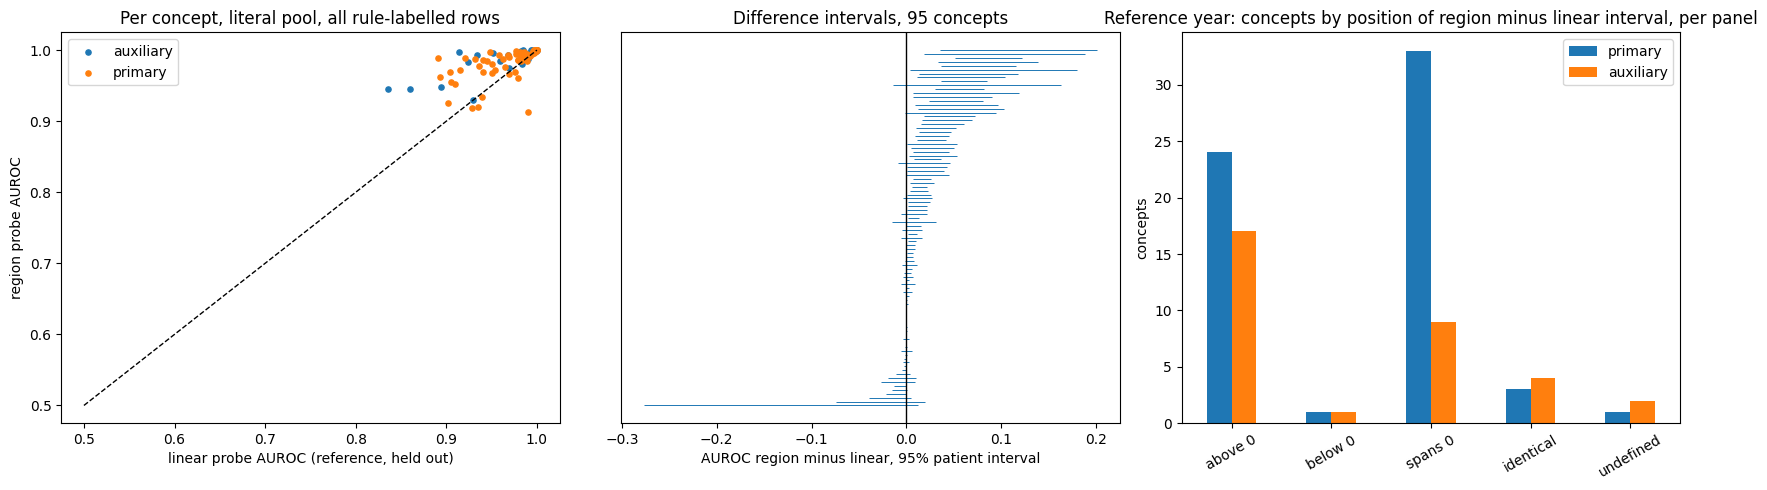

,primary,auxiliary
above 0,24.00,17.000
below 0,1.00,1.000
spans 0,33.00,9.000
identical,3.00,4.000
undefined,1.00,2.000
chance each side,1.45,0.675


In [16]:
REF = recognition[(recognition.pool == PRIMARY_POOL) & (recognition.population == "all")]
wide = REF.pivot_table(index=["build", "concept", "panel"], columns="quantity", values="point", aggfunc="first").reset_index()
DIFFERENCE = level_matrix("auroc:region-linear", PRIMARY_POOL, "all")
reference_counts = pd.DataFrame({panel: cr.position_counts(DIFFERENCE[cr.row_mask(ROWS, panel=panel, stage="reference")][:, 1:])
                                 for panel in ("primary", "auxiliary")})
fig, axes = plt.subplots(1, 3, figsize=(17, 5))
for panel, frame in wide.groupby("panel"):
    axes[0].scatter(frame["auroc:linear"], frame["auroc:region"], s=14, label=panel)
axes[0].plot([0.5, 1], [0.5, 1], "k--", lw=1)
axes[0].set_xlabel("linear probe AUROC (reference, held out)"); axes[0].set_ylabel("region probe AUROC"); axes[0].legend()
axes[0].set_title("Per concept, literal pool, all rule-labelled rows")
diffs = REF[REF.quantity == "auroc:region-linear"].sort_values("point").reset_index(drop=True)
axes[1].errorbar(diffs.point, range(len(diffs)), xerr=[np.clip(diffs.point - diffs.low, 0, None), np.clip(diffs.high - diffs.point, 0, None)], fmt="none", lw=0.7)
axes[1].axvline(0, color="k", lw=1); axes[1].set_xlabel("AUROC region minus linear, 95% patient interval"); axes[1].set_yticks([])
axes[1].set_title(f"Difference intervals, {len(diffs)} concepts")
reference_counts.loc[list(cr.POSITIONS)].plot.bar(ax=axes[2], rot=30)
axes[2].set_title("Reference year: concepts by position of region minus linear interval, per panel")
axes[2].set_ylabel("concepts")
save(fig, "step4_recognition")
display(reference_counts)


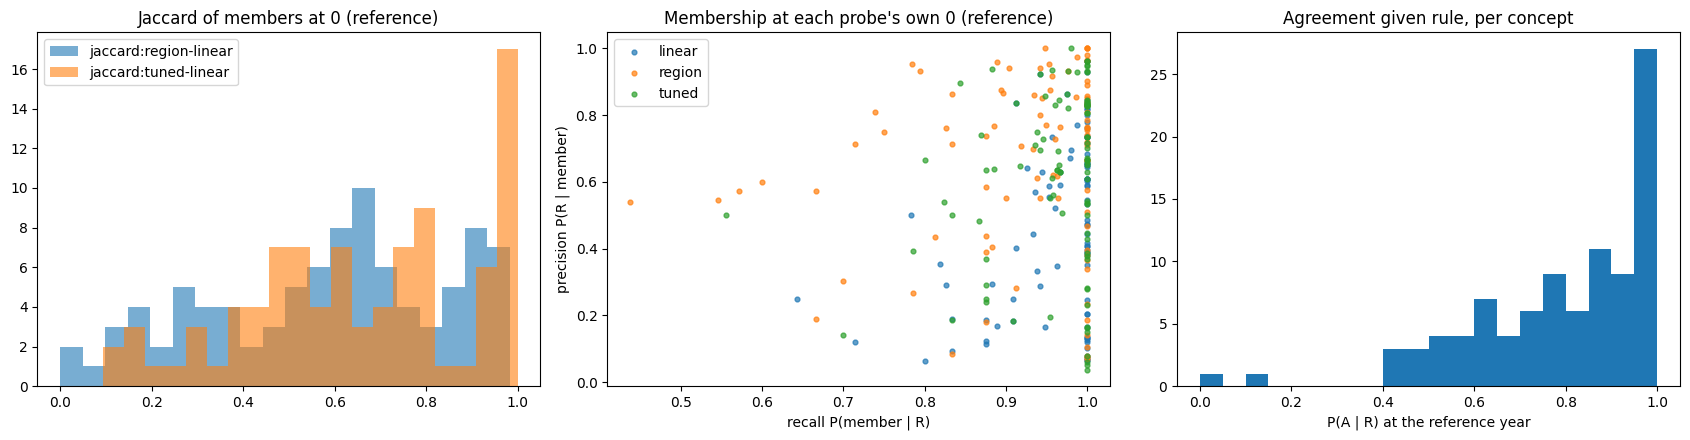

In [17]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
ref_members = membership[(membership.stage == "reference") & (membership.source == "sae") & (membership.pool == PRIMARY_POOL) & (membership.population == "all")]
for quantity in ("jaccard:region-linear", "jaccard:tuned-linear"):
    values = ref_members[ref_members.quantity == quantity].point.dropna()
    axes[0].hist(values, bins=20, alpha=0.6, label=quantity)
axes[0].set_title("Jaccard of members at 0 (reference)"); axes[0].legend()
for probe, colour in (("linear", "C0"), ("region", "C1"), ("tuned", "C2")):
    precision = ref_members[ref_members.quantity == f"precision:{probe}"].point
    recall = ref_members[ref_members.quantity == f"recall:{probe}"].point
    axes[1].scatter(recall.values, precision.values, s=12, color=colour, label=probe, alpha=0.7)
axes[1].set_xlabel("recall P(member | R)"); axes[1].set_ylabel("precision P(R | member)"); axes[1].legend()
axes[1].set_title("Membership at each probe's own 0 (reference)")
pa = ref_members[ref_members.quantity == "p_a_rule"].point
axes[2].hist(pa.dropna(), bins=20)
axes[2].set_xlabel("P(A | R) at the reference year"); axes[2].set_title("Agreement given rule, per concept")
save(fig, "step4_membership")


## Step 5. Transfer: frozen probes in 2012 to 2014, and 2015 as its own column

Question: does probe recognition of R decline over the same years as P(A | R), and do the probes differ on that decline? Trajectories are per build (the natural unit), and summaries are by years since the reference year. 2015 is shown as its own column and never pooled. P(A | R) is plotted on the same rows. AUROC and recall at 0 changes sit side by side, per build and by years since the reference year.

The point estimate can fall outside its bootstrap percentile interval, so the plotted error bars are clipped at 0 (plot only; the CSV tables hold the unclipped values).


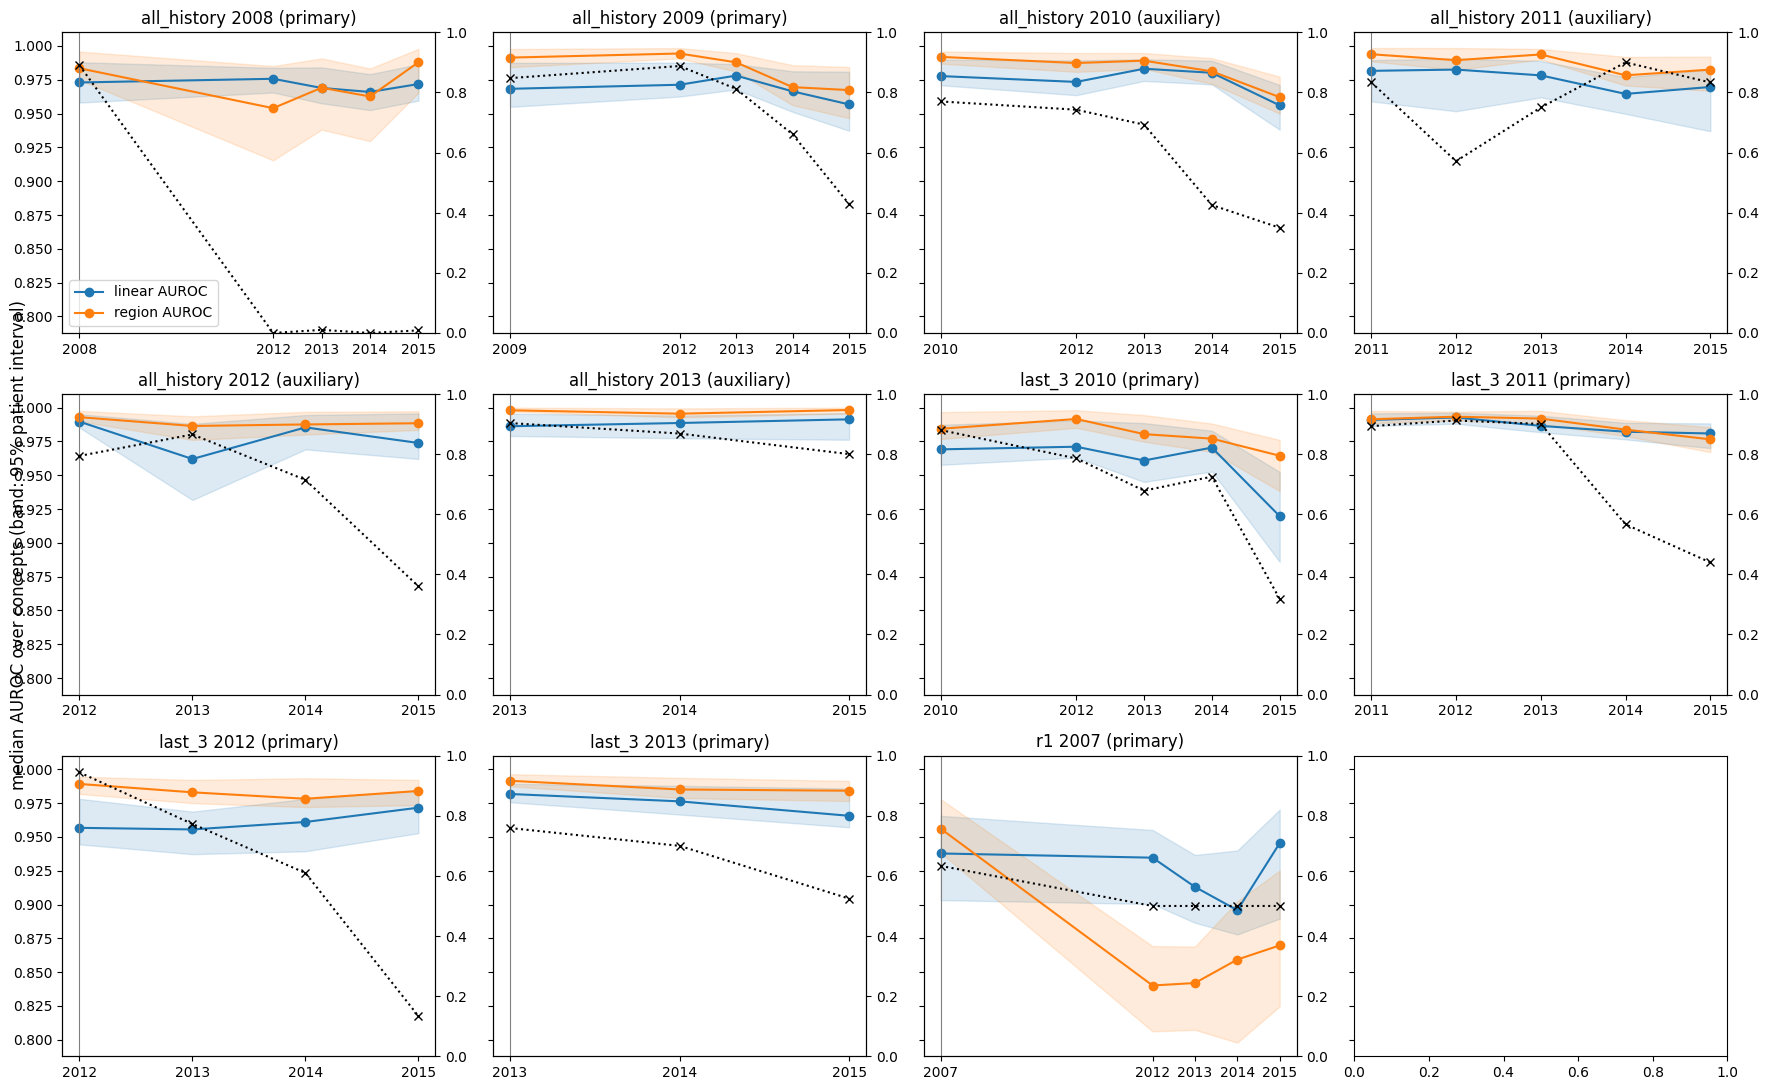

In [18]:
LEVEL_KEYS = {"linear": "auroc:linear", "tuned": "auroc:tuned", "region": "auroc:region"}


def median_row(mask, quantity, pool=PRIMARY_POOL, population="all", minus=None):
    """Median over the concepts in mask, per draw, with its interval; paired when minus names the other probe."""
    values = level_matrix(quantity, pool, population)[mask]
    if minus is not None:
        values = values - level_matrix(minus, pool, population)[mask]
    result = cr.median_by_draw(values)
    interval = cc.interval(result["median"][1:])
    return {"median": result["median"][0], "low": interval["low"], "high": interval["high"],
            "concepts": int(mask.sum()), "concepts_defined": int(result["defined"][0]),
            "undefined_fraction": float(result["undefined_fraction"][0])}


fig, axes = plt.subplots(3, 4, figsize=(18, 11), sharey=True)
for ax, (build, reference) in zip(axes.flat, BUILDS):
    if (build, reference) not in [(k[0], k[1]) for k in usable()]:
        ax.set_title(f"{build} {reference}: not run"); continue
    years = sorted(ROWS[(ROWS.build == build) & (ROWS.reference == reference)].year.unique())
    for probe, colour in (("linear", "C0"), ("region", "C1")):
        estimates = [median_row(cr.row_mask(ROWS, build=build, reference=reference, years_since=y - reference),
                                LEVEL_KEYS[probe]) for y in years]
        ax.plot(years, [e["median"] for e in estimates], marker="o", color=colour, label=f"{probe} AUROC")
        ax.fill_between(years, [e["low"] for e in estimates], [e["high"] for e in estimates], color=colour, alpha=0.15)
    twin = ax.twinx()
    agreement = [median_row(cr.row_mask(ROWS, build=build, reference=reference, years_since=y - reference),
                            "p_a_rule")["median"] for y in years]
    twin.plot(years, agreement, color="k", ls=":", marker="x", label="P(A | R)")
    twin.set_ylim(0, 1)
    ax.axvline(reference, color="grey", lw=0.8)
    ax.set_title(f"{build} {reference} ({PANEL[(build, reference)]})")
    ax.set_xticks(years)
axes.flat[0].legend(loc="lower left"); fig.supylabel("median AUROC over concepts (band: 95% patient interval)")
save(fig, "step5_trajectories_by_build")


## Step 5 (changes). Change from the reference by build: AUROC and recall at 0

Question: in each build, how far do the two probes' AUROC and recall at 0 move from the reference year, and how far does the region probe's change differ from the linear probe's? Transfer years are lines with 95% patient intervals. 2015 is drawn as hollow markers, never joined to the transfer years. The point estimate can fall outside its bootstrap percentile interval, so the plotted error bars are clipped at 0 (plot only; the CSV tables hold the unclipped values).

/home/rafaelgomes/SAE-TCAV/.venv/lib/python3.11/site-packages/matplotlib/cbook.py:1719: FutureWarning: Calling float on a single element Series is deprecated and will raise a TypeError in the future. Use float(ser.iloc[0]) instead
  return math.isfinite(val)
/home/rafaelgomes/SAE-TCAV/.venv/lib/python3.11/site-packages/matplotlib/cbook.py:1719: FutureWarning: Calling float on a single element Series is deprecated and will raise a TypeError in the future. Use float(ser.iloc[0]) instead
  return math.isfinite(val)
/home/rafaelgomes/SAE-TCAV/.venv/lib/python3.11/site-packages/matplotlib/cbook.py:1719: FutureWarning: Calling float on a single element Series is deprecated and will raise a TypeError in the future. Use float(ser.iloc[0]) instead
  return math.isfinite(val)
/home/rafaelgomes/SAE-TCAV/.venv/lib/python3.11/site-packages/matplotlib/cbook.py:1719: FutureWarning: Calling float on a single element Series is deprecated and will raise a TypeError in the future. Use float(ser.iloc[0]) 

/home/rafaelgomes/SAE-TCAV/.venv/lib/python3.11/site-packages/matplotlib/cbook.py:1719: FutureWarning: Calling float on a single element Series is deprecated and will raise a TypeError in the future. Use float(ser.iloc[0]) instead
  return math.isfinite(val)
/home/rafaelgomes/SAE-TCAV/.venv/lib/python3.11/site-packages/matplotlib/cbook.py:1719: FutureWarning: Calling float on a single element Series is deprecated and will raise a TypeError in the future. Use float(ser.iloc[0]) instead
  return math.isfinite(val)
/home/rafaelgomes/SAE-TCAV/.venv/lib/python3.11/site-packages/matplotlib/cbook.py:1719: FutureWarning: Calling float on a single element Series is deprecated and will raise a TypeError in the future. Use float(ser.iloc[0]) instead
  return math.isfinite(val)
/home/rafaelgomes/SAE-TCAV/.venv/lib/python3.11/site-packages/matplotlib/cbook.py:1719: FutureWarning: Calling float on a single element Series is deprecated and will raise a TypeError in the future. Use float(ser.iloc[0]) 

/home/rafaelgomes/SAE-TCAV/.venv/lib/python3.11/site-packages/matplotlib/cbook.py:1719: FutureWarning: Calling float on a single element Series is deprecated and will raise a TypeError in the future. Use float(ser.iloc[0]) instead
  return math.isfinite(val)
/home/rafaelgomes/SAE-TCAV/.venv/lib/python3.11/site-packages/matplotlib/cbook.py:1719: FutureWarning: Calling float on a single element Series is deprecated and will raise a TypeError in the future. Use float(ser.iloc[0]) instead
  return math.isfinite(val)
/home/rafaelgomes/SAE-TCAV/.venv/lib/python3.11/site-packages/matplotlib/cbook.py:1719: FutureWarning: Calling float on a single element Series is deprecated and will raise a TypeError in the future. Use float(ser.iloc[0]) instead
  return math.isfinite(val)
/home/rafaelgomes/SAE-TCAV/.venv/lib/python3.11/site-packages/matplotlib/cbook.py:1719: FutureWarning: Calling float on a single element Series is deprecated and will raise a TypeError in the future. Use float(ser.iloc[0]) 

/home/rafaelgomes/SAE-TCAV/.venv/lib/python3.11/site-packages/matplotlib/cbook.py:1719: FutureWarning: Calling float on a single element Series is deprecated and will raise a TypeError in the future. Use float(ser.iloc[0]) instead
  return math.isfinite(val)
/home/rafaelgomes/SAE-TCAV/.venv/lib/python3.11/site-packages/matplotlib/cbook.py:1719: FutureWarning: Calling float on a single element Series is deprecated and will raise a TypeError in the future. Use float(ser.iloc[0]) instead
  return math.isfinite(val)
/home/rafaelgomes/SAE-TCAV/.venv/lib/python3.11/site-packages/matplotlib/cbook.py:1719: FutureWarning: Calling float on a single element Series is deprecated and will raise a TypeError in the future. Use float(ser.iloc[0]) instead
  return math.isfinite(val)
/home/rafaelgomes/SAE-TCAV/.venv/lib/python3.11/site-packages/matplotlib/cbook.py:1719: FutureWarning: Calling float on a single element Series is deprecated and will raise a TypeError in the future. Use float(ser.iloc[0]) 

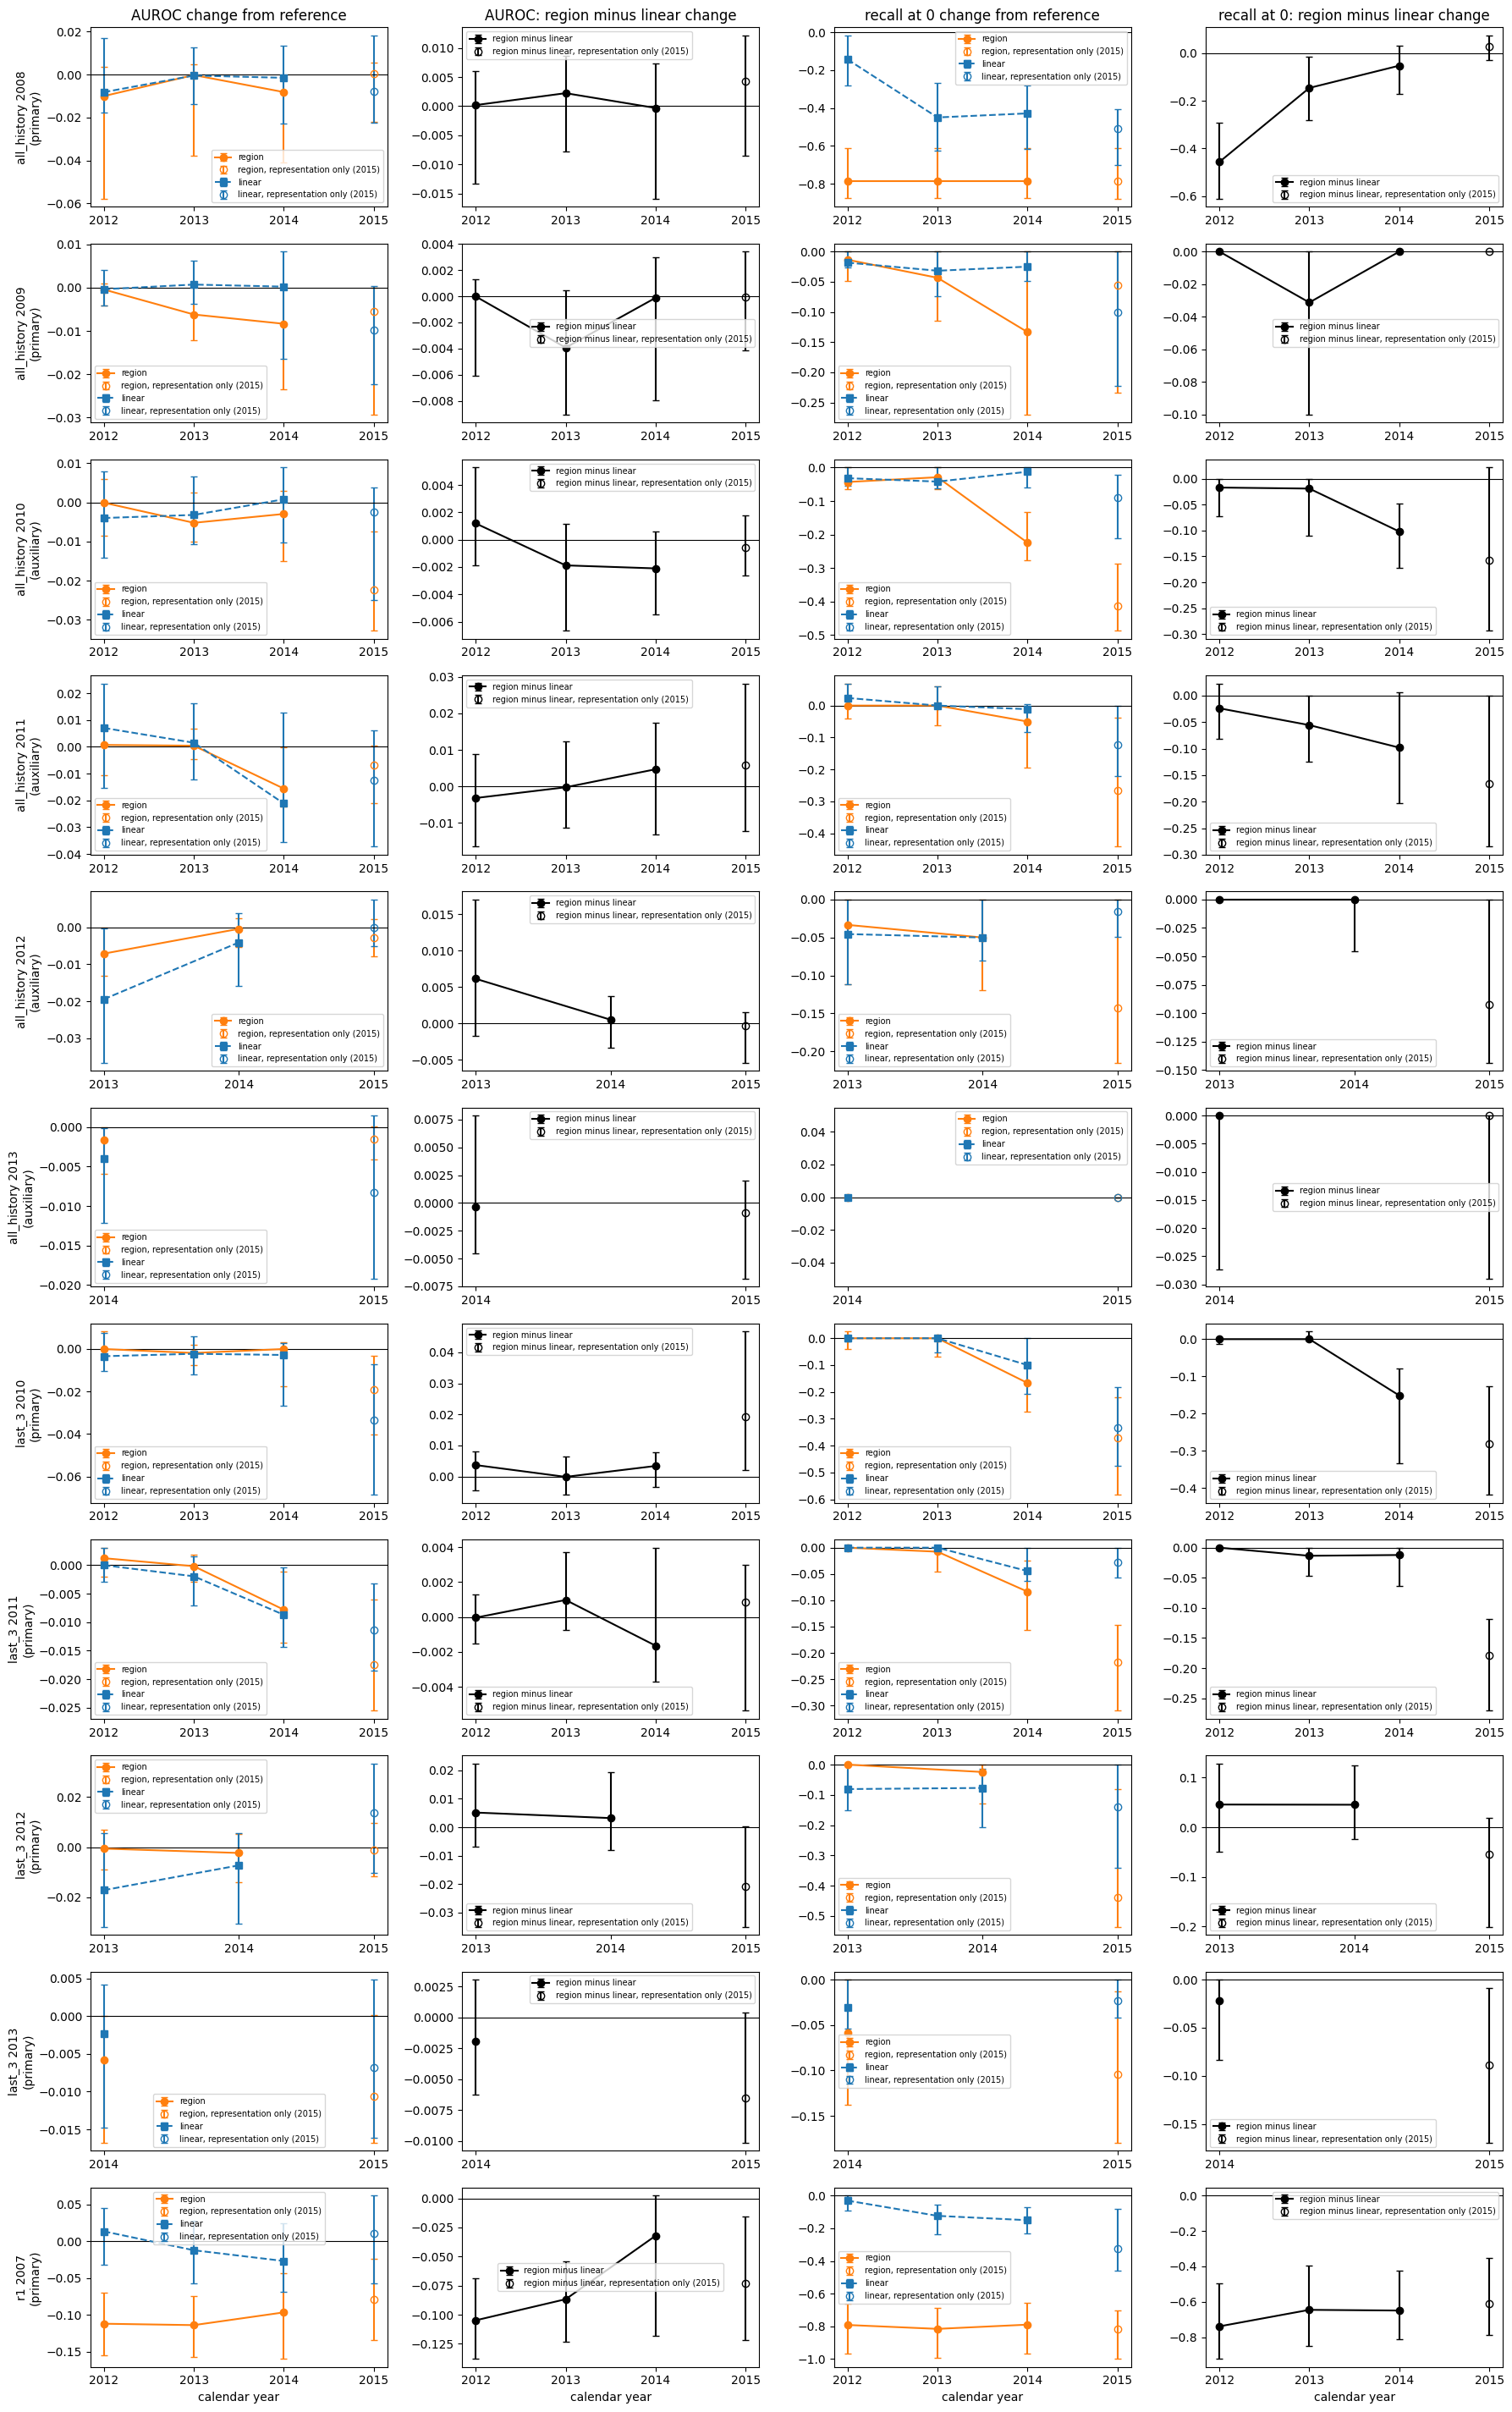

In [19]:
CHANGE_QUANTITIES = ("change auroc:linear", "change auroc:region", "change auroc:region - linear",
                     "change recall:linear", "change recall:region", "change recall:region - linear")
CHANGE_BY_BUILD = []
for build, reference in usable():
    for year in years_for(reference)[1:]:
        mask = cr.row_mask(ROWS, build=build, reference=reference) & (ROWS.year.values == year)
        if mask.sum() == 0:
            continue
        for quantity in CHANGE_QUANTITIES:
            CHANGE_BY_BUILD.append({"build": build, "reference": reference, "panel": PANEL[(build, reference)],
                                    "year": year, "stage": stage_of(year, reference), "quantity": quantity,
                                    **median_row(mask, quantity)})
CHANGES = pd.DataFrame(CHANGE_BY_BUILD)
table(CHANGES, "changes_by_build", show=False)


def draw_series(ax, frame, quantity, x, fmt, colour, label):
    """Transfer years as a line with intervals; 2015 (representation only) as hollow markers, never joined to the line."""
    for stage in ("transfer", "representation only"):
        part = frame[(frame.quantity == quantity) & (frame.stage == stage)].sort_values(x)
        if part.empty:
            continue
        yerr = [np.clip(part["median"] - part.low, 0, None), np.clip(part.high - part["median"], 0, None)]
        if stage == "transfer":
            ax.errorbar(part[x], part["median"], yerr=yerr, fmt=fmt, color=colour, capsize=3, label=label)
        else:
            ax.errorbar(part[x], part["median"], yerr=yerr, fmt="o", mfc="none", color=colour, capsize=3,
                        label=f"{label}, representation only (2015)")


fig, axes = plt.subplots(len(usable()), 4, figsize=(18, 2.6 * len(usable())), squeeze=False)
for row_axes, (build, reference) in zip(axes, usable()):
    part = CHANGES[(CHANGES.build == build) & (CHANGES.reference == reference)]
    draw_series(row_axes[0], part, "change auroc:region", "year", "o-", "C1", "region")
    draw_series(row_axes[0], part, "change auroc:linear", "year", "s--", "C0", "linear")
    draw_series(row_axes[1], part, "change auroc:region - linear", "year", "o-", "k", "region minus linear")
    draw_series(row_axes[2], part, "change recall:region", "year", "o-", "C1", "region")
    draw_series(row_axes[2], part, "change recall:linear", "year", "s--", "C0", "linear")
    draw_series(row_axes[3], part, "change recall:region - linear", "year", "o-", "k", "region minus linear")
    for ax in row_axes:
        ax.axhline(0, color="k", lw=0.8)
        ax.set_xticks(sorted(part.year.unique()))
        ax.legend(fontsize=7)
    row_axes[0].set_ylabel(f"{build} {reference}\n({PANEL[(build, reference)]})")
for ax, title in zip(axes[0], ("AUROC change from reference", "AUROC: region minus linear change",
                               "recall at 0 change from reference", "recall at 0: region minus linear change")):
    ax.set_title(title)
for ax in axes[-1]:
    ax.set_xlabel("calendar year")
save(fig, "step5_changes_by_build")


,panel,years_since_reference,stage,quantity,median,low,high,concepts,concepts_defined,undefined_fraction
0,primary,0,reference,auroc:region minus auroc:linear,0.006154,0.002438,0.008002,62,61,0.016129
6,primary,0,reference,p_a_rule,0.862407,0.815521,0.892857,62,62,0.000000
13,primary,1,transfer,auroc:region minus auroc:linear,0.002554,0.000665,0.006668,35,33,0.057143
19,primary,1,transfer,p_a_rule,0.736364,0.697462,0.830302,35,34,0.028571
26,primary,2,transfer,auroc:region minus auroc:linear,0.004067,0.002013,0.007596,28,27,0.035714
32,primary,2,transfer,p_a_rule,0.718421,0.644460,0.834094,28,28,0.000000
39,primary,2,representation only,auroc:region minus auroc:linear,0.010737,0.003033,0.016735,14,12,0.142857
45,primary,2,representation only,p_a_rule,0.524510,0.412368,0.638974,14,12,0.142857
52,primary,3,transfer,auroc:region minus auroc:linear,0.002024,0.000312,0.005444,31,31,0.000000
58,primary,3,transfer,p_a_rule,0.750000,0.662035,0.814509,31,31,0.000000


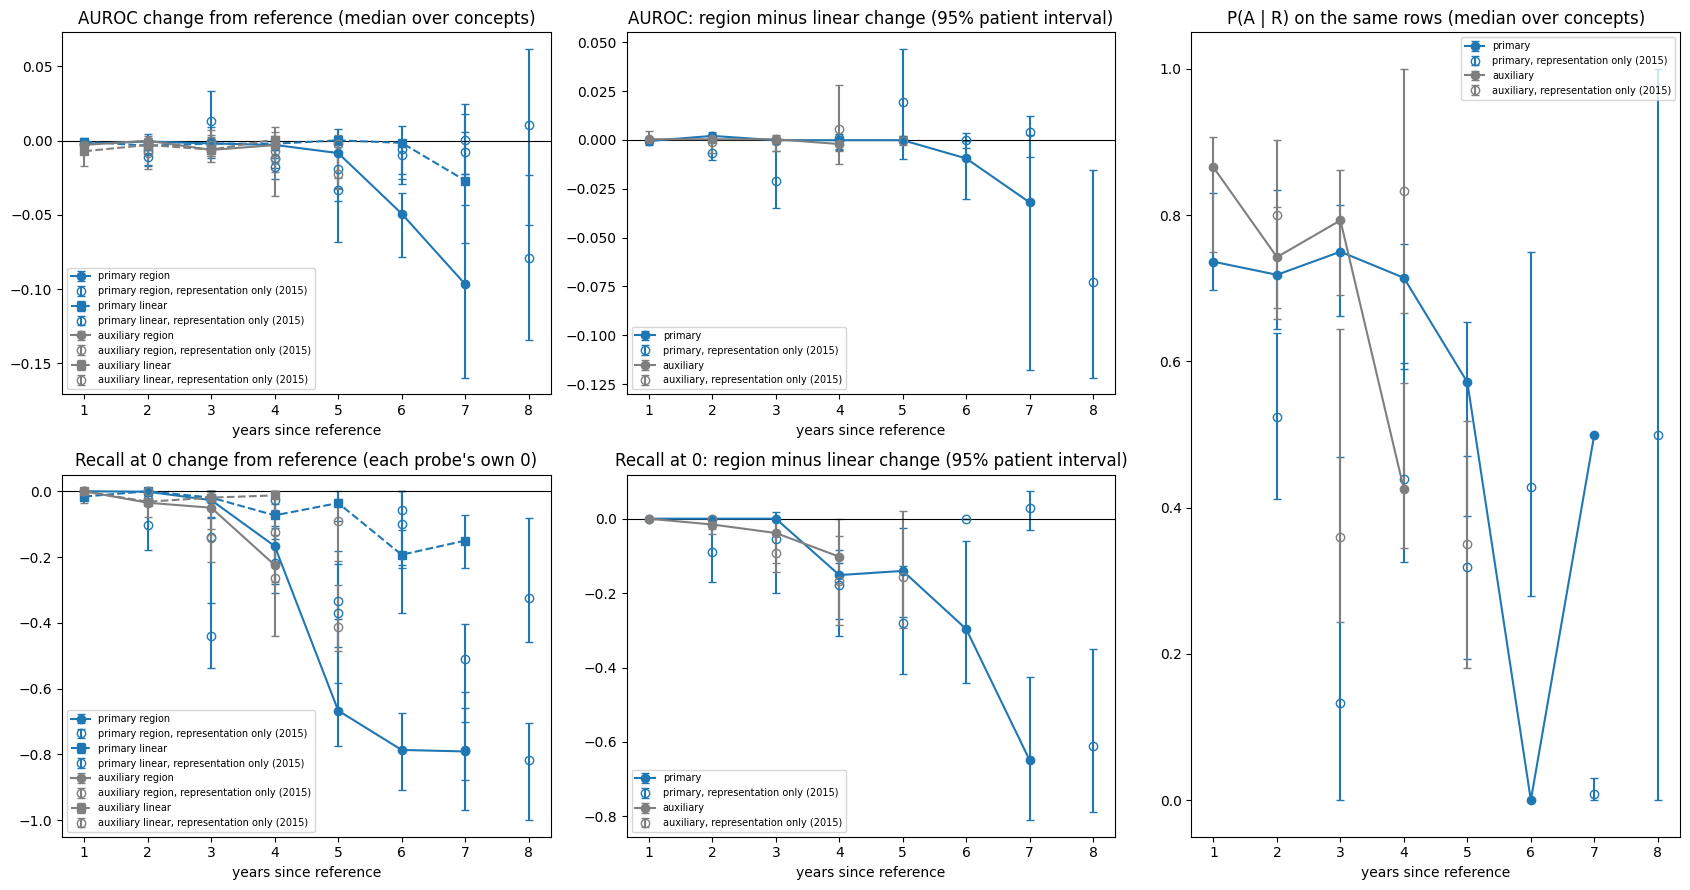

In [20]:
stage_rows = []
for panel in ("primary", "auxiliary"):
    for years_since in sorted(ROWS.years_since_reference.unique()):
        for stage in ("reference", "transfer", "representation only"):
            mask = cr.row_mask(ROWS, panel=panel, years_since=years_since, stage=stage)
            if mask.sum() == 0:
                continue
            for quantity, minus in (("auroc:region", "auroc:linear"), ("auroc:tuned", "auroc:linear"),
                                    ("auroc:region", "auroc:tuned")):
                stage_rows.append({"panel": panel, "years_since_reference": int(years_since), "stage": stage,
                                   "quantity": f"{quantity} minus {minus}", **median_row(mask, quantity, minus=minus)})
            for quantity in ("auroc:linear", "auroc:tuned", "auroc:region", "p_a_rule"):
                stage_rows.append({"panel": panel, "years_since_reference": int(years_since), "stage": stage,
                                   "quantity": quantity, **median_row(mask, quantity)})
            for quantity in ("change auroc:linear", "change auroc:region", "change auroc:region - linear",
                             "change recall:linear", "change recall:region", "change recall:region - linear"):
                stage_rows.append({"panel": panel, "years_since_reference": int(years_since), "stage": stage,
                                   "quantity": quantity, **median_row(mask, quantity)})
BY_YEARS_SINCE = pd.DataFrame(stage_rows)
table(BY_YEARS_SINCE, "summary_by_years_since_reference", show=False)
display(BY_YEARS_SINCE[BY_YEARS_SINCE.quantity.isin(["auroc:region minus auroc:linear", "p_a_rule"])].head(12))

fig = plt.figure(figsize=(17, 9))
grid = fig.add_gridspec(2, 3)
auroc_change, auroc_difference = fig.add_subplot(grid[0, 0]), fig.add_subplot(grid[0, 1])
recall_change, recall_difference = fig.add_subplot(grid[1, 0]), fig.add_subplot(grid[1, 1])
agreement = fig.add_subplot(grid[:, 2])
for panel, colour in (("primary", "C0"), ("auxiliary", "C7")):
    frame = BY_YEARS_SINCE[BY_YEARS_SINCE.panel == panel]
    draw_series(auroc_change, frame, "change auroc:region", "years_since_reference", "o-", colour, f"{panel} region")
    draw_series(auroc_change, frame, "change auroc:linear", "years_since_reference", "s--", colour, f"{panel} linear")
    draw_series(auroc_difference, frame, "change auroc:region - linear", "years_since_reference", "o-", colour, panel)
    draw_series(recall_change, frame, "change recall:region", "years_since_reference", "o-", colour, f"{panel} region")
    draw_series(recall_change, frame, "change recall:linear", "years_since_reference", "s--", colour, f"{panel} linear")
    draw_series(recall_difference, frame, "change recall:region - linear", "years_since_reference", "o-", colour, panel)
    draw_series(agreement, frame, "p_a_rule", "years_since_reference", "o-", colour, panel)
for ax in (auroc_change, auroc_difference, recall_change, recall_difference):
    ax.axhline(0, color="k", lw=0.8)
    ax.set_xlabel("years since reference")
    ax.legend(fontsize=7)
auroc_change.set_title("AUROC change from reference (median over concepts)")
auroc_difference.set_title("AUROC: region minus linear change (95% patient interval)")
recall_change.set_title("Recall at 0 change from reference (each probe's own 0)")
recall_difference.set_title("Recall at 0: region minus linear change (95% patient interval)")
agreement.set_title("P(A | R) on the same rows (median over concepts)")
agreement.set_xlabel("years since reference")
agreement.legend(fontsize=7)
save(fig, "step5_by_years_since_reference")

COUNT_ROWS = []
for panel in ("primary", "auxiliary"):
    for years_since in sorted(ROWS.years_since_reference.unique()):
        for stage in ("reference", "transfer", "representation only"):
            mask = cr.row_mask(ROWS, panel=panel, years_since=years_since, stage=stage)
            if mask.sum() == 0:
                continue
            COUNT_ROWS.append({"panel": panel, "years_since_reference": int(years_since), "stage": stage,
                               "concept_rows": int(mask.sum()), **cr.position_counts(DIFFERENCE[mask][:, 1:])})
table(pd.DataFrame(COUNT_ROWS), "concept_counts", show=False)

BUILD_COUNT_ROWS = []
for build, reference in usable():
    for year in years_for(reference):
        mask = cr.row_mask(ROWS, build=build, reference=reference) & (ROWS.year.values == year)
        if mask.sum() == 0:
            continue
        BUILD_COUNT_ROWS.append({"build": build, "reference": reference, "panel": PANEL[(build, reference)], "year": year,
                                 "stage": stage_of(year, reference), "concept_rows": int(mask.sum()),
                                 **cr.position_counts(DIFFERENCE[mask][:, 1:])})
table(pd.DataFrame(BUILD_COUNT_ROWS), "concept_counts_by_build", show=False)


## Step 6. Random-direction control

Question: do the random-direction candidates show the same region-minus-linear pattern as the SAE concepts? Literal pool, all rule-labelled rows only, the same grids, selection and draws. P(A | member) and P(A | R) are not applicable to random candidates and are written as such.

The point estimate can fall outside its bootstrap percentile interval, so the plotted error bars are clipped at 0 (plot only; the CSV tables hold the unclipped values).


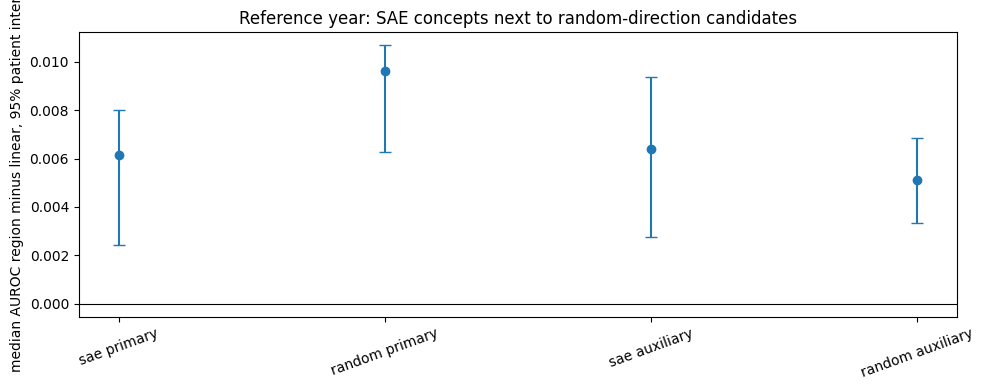

In [21]:
RANDOM_ROWS = []
for panel in ("primary", "auxiliary"):
    for stage in ("reference", "transfer", "representation only"):
        for group in ("sae", "random"):
            for years_since in sorted(ROWS.years_since_reference.unique()):
                mask = cr.row_mask(ROWS, group=group, panel=panel, years_since=years_since, stage=stage)
                if mask.sum() == 0:
                    continue
                for quantity, minus in (("auroc:region", "auroc:linear"), ("auroc:linear", None), ("auroc:region", None),
                                        ("auroc:tuned", None), ("auroc:tuned", "auroc:linear"),
                                        ("auroc:region", "auroc:tuned"), ("change auroc:region - linear", None)):
                    row = median_row(mask, quantity, minus=minus)
                    RANDOM_ROWS.append({"group": group, "panel": panel, "stage": stage, "years_since_reference": int(years_since),
                                        "quantity": quantity + (f" minus {minus}" if minus else ""), **row})
                if group == "random":
                    for quantity in ("p_a_member", "p_a_rule"):
                        RANDOM_ROWS.append({"group": group, "panel": panel, "stage": stage, "years_since_reference": int(years_since),
                                            "quantity": quantity, "median": "not applicable (no activation for random candidates)"})
RANDOM_CONTROL = pd.DataFrame(RANDOM_ROWS)
table(RANDOM_CONTROL, "random_control", show=False)

ref_control = RANDOM_CONTROL[(RANDOM_CONTROL.stage == "reference") & (RANDOM_CONTROL.quantity == "auroc:region minus auroc:linear")]
fig, ax = plt.subplots(figsize=(10, 4))
positions_x = np.arange(len(ref_control))
ref_control = ref_control.assign(label=ref_control["group"] + " " + ref_control.panel)
ax.errorbar(positions_x, ref_control["median"], yerr=[np.clip(ref_control["median"] - ref_control.low, 0, None), np.clip(ref_control.high - ref_control["median"], 0, None)], fmt="o", capsize=4)
ax.set_xticks(positions_x, ref_control.label, rotation=20); ax.axhline(0, color="k", lw=0.8)
ax.set_ylabel("median AUROC region minus linear, 95% patient interval")
ax.set_title("Reference year: SAE concepts next to random-direction candidates")
save(fig, "step6_random_control")


## Step 7. Overfitting view, summaries, figures and the run record

Question: how much of each probe's apparent quality is selection optimism? Fit-row, selection and held-out AUROC sit side by side for the chosen settings, and the selection gain over each probe's anchor is shown: region over the sklearn default setting (raw, C = 1, gamma = scale), tuned linear over the fixed linear setting (raw, C = 0.1). Held-out AUROC is the unbiased contrast; the selection gain is optimistic by construction (the maximum of noisy AUROCs).


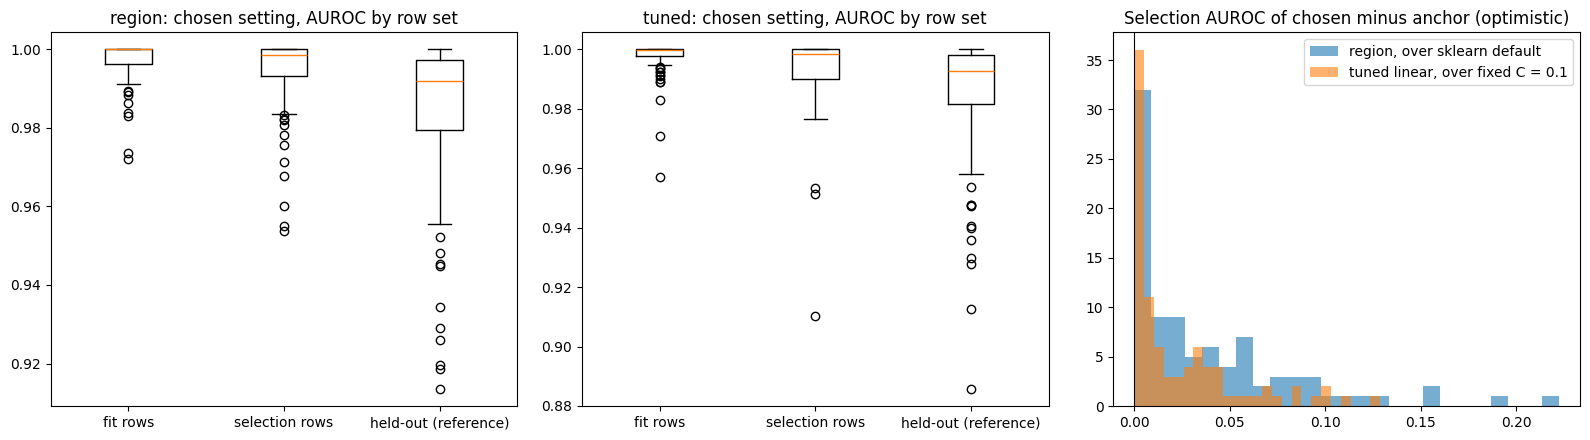

In [22]:
held_out = {p: {} for p in ("region", "tuned")}
for key, values in VALUES.items():
    build, reference, source, concept, pool, year, population, quantity = key
    if source == "sae" and pool == PRIMARY_POOL and population == "all" and year == reference:
        for probe in held_out:
            if quantity == f"auroc:{probe}":
                held_out[probe][(build, reference, concept)] = values[0]
# Gain of the chosen setting over the probe's own anchor: region over the sklearn default, tuned linear over the fixed C = 0.1.
GAIN_COLUMN = {"region": "selection_gain_over_sklearn_default", "tuned": "selection_gain_over_fixed_C_0_1"}
overfit = []
for probe in ("region", "tuned"):
    chosen_rows = tuning_df[tuning_df.chosen & (tuning_df.probe == ("region" if probe == "region" else "tuned_linear"))
                            & (tuning_df.pool == PRIMARY_POOL) & (tuning_df.source == "sae")]
    anchor_position = str(cr.REGION_ANCHOR if probe == "region" else cr.LINEAR_ANCHOR)
    anchors_rows = tuning_df[(tuning_df.probe == ("region" if probe == "region" else "tuned_linear"))
                             & (tuning_df.position == anchor_position) & (tuning_df.pool == PRIMARY_POOL) & (tuning_df.source == "sae")]
    anchor_by_concept = anchors_rows.set_index(["build", "reference", "concept"]).selection_auroc
    for _, row in chosen_rows.iterrows():
        k = (row.build, row.reference, row.concept)
        overfit.append({"probe": probe, "build": row.build, "reference": row.reference, "concept": row.concept,
                        "fit_auroc": row.fit_auroc, "selection_auroc": row.selection_auroc,
                        "held_out_auroc": held_out[probe].get(k, np.nan),
                        GAIN_COLUMN[probe]: row.selection_auroc - anchor_by_concept.get(k, np.nan)})
OVERFIT = pd.DataFrame(overfit)
table(OVERFIT, "overfitting", show=False)
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, probe in zip(axes[:2], ("region", "tuned")):
    frame = OVERFIT[OVERFIT.probe == probe]
    ax.boxplot([frame.fit_auroc.dropna(), frame.selection_auroc.dropna(), frame.held_out_auroc.dropna()])
    ax.set_xticks([1, 2, 3], ["fit rows", "selection rows", "held-out (reference)"])
    ax.set_title(f"{probe}: chosen setting, AUROC by row set")
axes[2].hist(OVERFIT[OVERFIT.probe == "region"][GAIN_COLUMN["region"]].dropna(), bins=25, alpha=0.6, label="region, over sklearn default")
axes[2].hist(OVERFIT[OVERFIT.probe == "tuned"][GAIN_COLUMN["tuned"]].dropna(), bins=25, alpha=0.6, label="tuned linear, over fixed C = 0.1")
axes[2].axvline(0, color="k", lw=0.8); axes[2].legend()
axes[2].set_title("Selection AUROC of chosen minus anchor (optimistic)")
save(fig, "step7_overfitting")


In [23]:
BY_BUILD = []
for build, reference in usable():
    for pool in POOLS:
        for year in years_for(reference):
            mask = cr.row_mask(ROWS, build=build, reference=reference) & (ROWS.year.values == year)
            if mask.sum() == 0:
                continue
            for quantity, minus in (("auroc:region", "auroc:linear"), ("auroc:tuned", "auroc:linear"),
                                    ("auroc:region", "auroc:tuned"), ("auroc:linear", None), ("auroc:region", None),
                                    ("recall:region", "recall:linear"), ("recall:linear", None), ("p_a_rule", None),
                                    ("change auroc:region - linear", None)):
                BY_BUILD.append({"build": build, "reference": reference, "panel": PANEL[(build, reference)],
                                 "pool": pool, "year": year, "stage": stage_of(year, reference),
                                 "quantity": quantity + (f" minus {minus}" if minus else ""),
                                 **median_row(mask, quantity, pool=pool, minus=minus)})
table(pd.DataFrame(BY_BUILD), "summary_by_build", show=False)
print("summary_by_build rows:", len(BY_BUILD))


summary_by_build rows: 882


In [24]:
private = OUTPUT / "private"
private.mkdir(exist_ok=True)
probes_saved = {}
for key in usable():
    for c in STATE[key]["concepts"]:
        if c["source"] != "sae":
            continue
        for pool in c["pools"]:
            fits = c["fits"][pool]
            probes_saved[(key[0], key[1], c["concept"], pool)] = {
                "region": fits["region"]["setting"]["pipeline"] if fits["region"]["setting"] else None,
                "tuned_linear": fits["linear"]["setting"]["pipeline"] if fits["linear"]["setting"] else None,
                "declared_linear": (c["saved"][pool].get("coef"), c["saved"][pool].get("intercept"))}
with open(private / "region_probes.pkl", "wb") as handle:
    pickle.dump({"sklearn": sklearn.__version__, "probes": probes_saved}, handle)
print("private probes saved (Fiji only):", len(probes_saved))


private probes saved (Fiji only): 190


In [25]:
run = {"work": "linear-cav-vs-concept-regions", "notebook": "concept_regions.ipynb",
       "commit": subprocess.run(["git", "rev-parse", "HEAD"], capture_output=True, text=True, cwd=ROOT).stdout.strip(),
       "notebook_sha256": cr.sha256(ROOT / "concept_regions.ipynb"),
       "code_sha256": {"concept_regions.py": cr.sha256(ROOT / "concept_regions.py"),
                       "tests/test_concept_regions.py": cr.sha256(ROOT / "tests/test_concept_regions.py")},
       "build_set": BUILD_SET, "builds": [list(b) for b in BUILDS], "builds_used": [list(k) for k in usable()],
       "panel": {f"{b} {r}": PANEL[(b, r)] for b, r in BUILDS},
       "gate": gate_rows, "recorded": RECORDED, "rule_quality": RULE_QUALITY_RECORD, "environment": ENVIRONMENT,
       "device": "cuda for the AUROC readouts; CPU for SVC and liblinear fits", "workers": WORKERS,
       "blas_threads_per_worker": 1, "draws": len(cc.BOOTSTRAP_SEEDS), "bootstrap_seeds": [cc.BOOTSTRAP_SEEDS[0], cc.BOOTSTRAP_SEEDS[-1]],
       "draw_set": "one population-wide set (plan decision 10)",
       "split_seed": {f"{b} {r}": STATE[(b, r)]["split_seed"] for b, r in usable()},
       "anchors": ANCHORS, "gpu_smoke": GPU_SMOKE, "gpu_per_build": GPU_LOG,
       "timings_seconds": TIMINGS, "total_seconds": round(time.time() - STARTED, 1),
       "peak_rss_mb": resource.getrusage(resource.RUSAGE_SELF).ru_maxrss / 1024,
       "errors": ERRORS, "output_files": sorted(p.name for p in OUTPUT.iterdir() if p.is_file())}
(OUTPUT / "run.json").write_text(json.dumps(run, indent=1, default=str))
print(json.dumps({k: run[k] for k in ("build_set", "builds_used", "total_seconds", "peak_rss_mb", "errors")}, indent=1, default=str))


{
 "build_set": "all",
 "builds_used": [
  [
   "all_history",
   2008
  ],
  [
   "all_history",
   2009
  ],
  [
   "all_history",
   2010
  ],
  [
   "all_history",
   2011
  ],
  [
   "all_history",
   2012
  ],
  [
   "all_history",
   2013
  ],
  [
   "last_3",
   2010
  ],
  [
   "last_3",
   2011
  ],
  [
   "last_3",
   2012
  ],
  [
   "last_3",
   2013
  ],
  [
   "r1",
   2007
  ]
 ],
 "total_seconds": 89.2,
 "peak_rss_mb": 2964.515625,
 "errors": []
}
